# AHU fault detection and diagnosis

One notebook holds the whole analysis, in the order the work was done. Section 0 sets the problem and the success
measures. Sections 1 to 6 answer Question 1 of the brief (data, quality checks, patterns and fault signatures, on January to
June). Sections 7 to 15 answer Question 2 (model, validation, results, comparison with simpler methods, error analysis
and the final predictions). Sections 16 to 21 open the test period for unlabelled leads, then cover behaviour tests, the
maintenance team's view, the model bundle, monitoring and the conclusions.

Figures are written to `../../report/figures/` for the report. A full run takes about 45 minutes, most of it the five-seed
check and the nested tuning.

## 0. Problem and success measures

**The problem.** The client runs 40 AHUs in an office, a hospital and a mall. Faults such as a stuck valve, a stuck damper,
a drifting sensor or a fouled coil keep the BMS running as if nothing happened, waste energy and are often found weeks
later after a complaint. The client wants faults found while they are happening, named correctly, and passed to the
maintenance team without burying the technicians in false alarms.

**What happens when an alarm fires.** The alarm becomes one ticket in the maintenance system with the AHU, the fault type,
the start time and the evidence chart. A technician visits and checks the named component (valve stroke, damper linkage,
supply-air sensor against a handheld probe, coil and isolation valve). The visit outcome becomes the label for the next
training run. A false alarm therefore costs a full wasted visit, and a wrong type sends the technician to the wrong part
of the unit, which costs time on site but still finds the unit faulty.

**How success is measured.** The brief scores events the way the maintenance team sees them, and this notebook uses the
same four numbers.

| Measure | Definition | Why it matters |
|---|---|---|
| Found | share of labelled events with at least one alarm row while the event is open | a missed fault keeps wasting energy |
| Right type | share of events where the most frequent alarm type inside the event is the true type | the technician goes to the right component |
| Delay | median hours from the labelled start to the first alarm | comfort complaints start within hours for some faults |
| False alarms | alarm runs that touch no labelled event, per AHU-month | each one is a wasted site visit |

For tuning, the four become one number, `J = right-type share − 4 × false alarms per AHU-month`. The weight of 4 is my
assumption, not the client's. It says that 0.05 false alarms per AHU-month (about 2 wasted visits a month across the
fleet) costs as much as missing the type on one fault in five.

**Why J and not a formula in money.** A published formula for exactly this question exists, the figure of merit of Yuill
and Braun (2017), which adds up the money a fault detector saves and subtracts the service visits it wastes. I price it at
Indonesian rates in section 18 and still tune on J, for three reasons. The money needs inputs I could only estimate (hours
per visit, the chance that a technician finds a fault the alarm did not name) and leaves out comfort, which is often why a
fault gets reported at all. It also barely separates the alarm settings, since all 16 land within about 5% of each other in
the central scenario, and its ranking of them changes with the price scenario (rank correlation with J of 0.61, 0.22 and
0.03). J needs no prices, so it carries to any building unchanged. Where it matters the two agree. In rupiah a false alarm
costs as much as 0.42 right-typed faults earn, and the weight of 4 in J prices it at 0.47, so I keep the weight and report
the rupiah figure next to J. That agreement holds in the central price scenario only. In the optimistic one the two
rankings barely agree (0.03) and money would pick a different setting, but the gap between the two picks is about Rp400
per AHU-month (section 18), so the choice of J costs little either way. The weight itself still needs the client's sign-off.

**Today's baseline.** The buildings run a supply-air temperature alarm in the BMS, which says that something is wrong but
never what. A set of expert rules in the spirit of APAR (House et al., 2001) is the second baseline, standing in for what
an engineer would write by hand. A logistic regression on the same features as the model is the third comparison, showing how much a simple linear model gets from the same evidence. All three go through the same alarm logic and scorer as the model in section 11.

**Proposed targets, to be agreed with the client.** These are my proposal for the pilot, not targets the client has set.
The maintenance lead (fewer visits) and the energy manager (every fault found) will likely weigh them differently, and the
false-alarm weight in `J` is the place to settle that.

| Measure | Proposed target | Source of the number |
|---|---|---|
| Found | at least 80% of labelled faults | well above today's alarm, which finds 14 of 28 in section 11 |
| Right type | at least 70% | a technician who is sent to the right component three times in four saves a second trip |
| Delay | median under 24 hours | slow faults waste energy over days, fast ones are caught in hours |
| False alarms | at most 0.05 per AHU-month | about 2 wasted visits a month across 40 AHUs |
| Against today | better than the BMS alarm on found and false alarms, tested event by event | otherwise there is no reason to change |

**Out of scope.** Fault types other than the four labelled ones (fan belt, filter, chiller plant, zone faults), the cost of lost
comfort and a severity ranking of faults (section 18 prices energy and site visits only), the root cause behind the component (why the valve stuck), any automatic change to the BMS
(the model only reads), filter replacement planning, detection faster than the 5-minute log, and new sensors. Requests in
these areas go onto a list for after the pilot rather than into this model.

**Time box.** The brief allows 48 hours for this analysis. The pilot plan, with its own gates, is in Q3 and Q4 of the report.

The next cell loads the libraries and the project code in `src/ahu_fdd`, sets the figure style and reads the raw log and the AHU metadata.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ahu_fdd import pipeline as PL, features as F, events as E, experiments as X
from ahu_fdd.config import CLASSES, FAULTS, CODE_DIR, load_labels, load_metadata
from ahu_fdd.clean import load_all_raw, load_clean
from ahu_fdd.features import add_physics

FIG = CODE_DIR.parent / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
meta, labels = load_metadata(), load_labels()
raw = load_all_raw()

The next cell records the Python version, the library versions and the seed, so every number below can be
rebuilt with the same software.

In [2]:
import platform, importlib.metadata as im
SEED = 0  # classifier seed. The LightGBM regressors use the library's fixed default seed.
print("python", platform.python_version(), "| classifier seed", SEED, "| post-processing", PL.POST)
pd.Series({p: im.version(p) for p in ["pandas", "numpy", "pyarrow", "scikit-learn", "lightgbm", "scipy", "matplotlib"]}, name="version")

python 3.12.13 | classifier seed 0 | post-processing {'t_on': 0.8, 't_off': 0.3, 'smooth': 12, 'hold': 144}


pandas           3.1.1
numpy            2.5.4
pyarrow         26.0.1
scikit-learn     1.9.1
lightgbm         4.7.0
scipy           1.18.1
matplotlib      3.11.2
Name: version, dtype: str

The run uses Python 3.12.13 with pandas 3.1.1, numpy 2.5.4, pyarrow 26.0.1, scikit-learn 1.9.1, LightGBM 4.7.0
and scipy 1.18.1, the same versions pinned in `requirements.txt`. The classifier seed is 0 and the LightGBM regressors use
their fixed default seed. Running `run.py` twice gives the same `predictions.csv` byte for byte (same SHA-256 hash).

## 1. Data, unit of observation and data dictionary

**Unit of observation.** One row is one AHU at one 5-minute timestamp in local time (UTC+8). Rows are grouped by AHU
(40 units) and by building (16 office, 12 hospital and 12 mall units). Consecutive rows of one AHU are strongly
correlated, so later splits are by whole months or by whole AHUs, never by random row.

**The test period.** July and August carry no labels. Their inputs are only checked for quality (sections 2
and 3), and every pattern in sections 4 and 5 uses January to June only, so nothing seen in the test period shapes the
model. The test period is opened for patterns once, after the final model is fixed (section 16).

**Personal data.** None. The data holds equipment readings and AHU identifiers. Work orders carry no technician names.

**Data dictionary.** Every column with its meaning, unit, typical range, source and, for derived columns, its formula
is in `code/DATA_DICTIONARY.md`. The table below is computed from the data and is the source of the ranges there.

In [3]:
clean_df = load_clean()
run_rows = clean_df[clean_df.fan_status == 1]
sig = [c for c in raw.columns if c not in ("timestamp", "ahu_id", "split")]
bldg = raw.ahu_id.str[:2]
quality = pd.DataFrame({
    "dtype": raw[sig].dtypes.astype(str),
    "raw_missing_pct": raw[sig].isna().mean() * 100,
    "clean_missing_pct": clean_df[sig].isna().mean() * 100,
    "p1_running": run_rows[sig].quantile(0.01),
    "p99_running": run_rows[sig].quantile(0.99),
    "min": clean_df[sig].min(), "max": clean_df[sig].max(),
    "buildings_logged": [",".join(sorted(bldg[raw[c].notna()].unique())) for c in sig],
})
print(f"{len(raw):,} raw rows, {len(clean_df):,} after cleaning, fan off in {(clean_df.fan_status == 0).mean():.1%} of rows")
quality.round(2)

2,765,527 raw rows, 2,762,088 after cleaning, fan off in 35.4% of rows


,dtype,raw_missing_pct,clean_missing_pct,p1_running,p99_running,min,max,buildings_logged
fan_status,int8,0.00,0.00,1.00,1.00,0.000000,1.000000,"B1,B2,B3"
fan_speed_pct,float32,0.00,0.00,35.00,100.00,0.000000,100.000000,"B1,B2,B3"
fan_power_kw,float32,0.15,0.15,0.36,25.64,0.040000,30.760000,"B1,B2,B3"
supply_static_pa,float32,0.00,0.00,192.00,329.00,0.000000,350.000000,"B1,B2,B3"
supply_static_sp_pa,float32,0.00,0.00,220.00,320.00,0.000000,320.000000,"B1,B2,B3"
sat_c,float32,0.15,0.24,12.10,18.10,6.900000,32.599998,"B1,B2,B3"
sat_sp_c,float32,0.00,0.00,12.50,14.50,12.500000,14.500000,"B1,B2,B3"
mat_c,float32,0.15,0.15,22.10,26.20,20.900000,31.900000,"B1,B2,B3"
rat_c,float32,0.15,0.23,21.80,25.60,20.700001,31.600000,"B1,B2,B3"
zone_temp_sp_c,float32,0.00,0.00,23.00,25.00,23.000000,25.000000,"B1,B2,B3"


Of the 18 signal columns, 11 have no missing values at all. `co2_ppm` is missing in 30.4% of rows and `sa_flow_m3h` in
70.8%, and the last column of the table shows why. CO2 is only logged in B1 and B2, and airflow only in B2, so these gaps
mean "sensor not fitted", not "reading lost". The model gets this as the flags `has_co2` and `has_flow`.

Five signals (`fan_power_kw`, `sat_c`, `mat_c`, `rat_c`, `chw_valve_cmd_pct`) each lose about 0.15% of rows. These are single
samples, spread evenly over all 40 units and all six training months, never longer than three rows, and absent in the test
period. They look like random logging dropouts, so they are left as NaN rather than filled. After cleaning, `sat_c` rises to
0.24% and `rat_c` to 0.23% missing, because the frozen-sensor periods found in section 3 are masked.

Typical running ranges are physically sensible. Supply air sits at 12.1 to 18.1 °C against setpoints of 12.5 to 14.5 °C,
mixed air at 22.1 to 26.2 °C, and chilled water at 6.2 to 8.2 °C. The hard limits (supply air up to 32.6 °C, fan speed down to 0%)
come from start-ups and faults, which is why the model only learns from steady rows. The fan is off in 35.4% of rows, which
matches the office and mall schedules, and those rows are not scored.

## 2. Structure and coverage

In [4]:
expected = raw.groupby(["split", "ahu_id"])["timestamp"].agg(["min", "max", "size"])
expected["expected"] = ((expected["max"] - expected["min"]) / pd.Timedelta("5min") + 1).astype(int)
print(raw.shape)
print(expected.groupby(level=0)[["size", "expected"]].sum())
print("NaN share per column (train):")
print(raw[raw.split == "train"].isna().mean().loc[lambda s: s > 0].round(4))
print(meta.groupby("building")[["has_co2_sensor", "has_airflow_station"]].mean())
print(labels.fault_type.value_counts())
uniq = raw.drop_duplicates(["ahu_id", "timestamp"]).sort_values(["ahu_id", "timestamp"])
full = {"train": 40 * 181 * 288, "test": 40 * 62 * 288}  # every AHU every 5 minutes, 1 Jan to 30 Jun and 1 Jul to 31 Aug
print("unique rows against the full calendar:", {s: f"{n:,} of {full[s]:,} ({n / full[s]:.2%})" for s, n in uniq.split.value_counts().items()})
step = uniq.groupby("ahu_id").timestamp.diff()
gaps = (step[step > pd.Timedelta("5min")] / pd.Timedelta("5min") - 1).astype(int)
print("gaps by number of missing rows:")
print(pd.crosstab(pd.cut(gaps, [0, 1, 12, 100, np.inf], labels=["1 row", "2 to 12", "13 to 100", "over 100"]), uniq.split[gaps.index]))
core = ["fan_power_kw", "sat_c", "mat_c", "rat_c", "chw_valve_cmd_pct"]
miss = uniq[core].isna().any(axis=1)
drop_runs = miss[miss].groupby((miss != miss.groupby(uniq.ahu_id).shift()).cumsum()[miss]).size()
print(f"core-signal dropouts: {len(drop_runs):,} runs, {(drop_runs == 1).sum():,} of them a single row, longest {drop_runs.max()} rows;",
      "signals lost per dropout row:", uniq.loc[miss, core].isna().sum(axis=1).value_counts().to_dict())
by_ahu = miss[uniq.split == "train"].groupby(uniq.ahu_id).mean()
print("share of rows with a core dropout, by month:", miss.groupby(uniq.timestamp.dt.month).mean().round(4).to_dict(),
      f"| per AHU {by_ahu.min():.2%} to {by_ahu.max():.2%}")
print("NaN share per column (test):", uniq[uniq.split == "test"].isna().mean().loc[lambda s: s > 0].round(4).to_dict())

(2765527, 21)
          size  expected
split                   
test    711994    714239
train  2053533   2085120
NaN share per column (train):
fan_power_kw         0.0020
sat_c                0.0020
mat_c                0.0020
rat_c                0.0020
chw_valve_cmd_pct    0.0020
co2_ppm              0.3054
sa_flow_m3h          0.7103
dtype: float64
          has_co2_sensor  has_airflow_station
building                                     
B1                   1.0                  0.0
B2                   1.0                  1.0
B3                   0.0                  0.0
fault_type
chw_valve_stuck      8
oa_damper_stuck      7
low_coil_capacity    7
sat_sensor_bias      6
Name: count, dtype: int64


unique rows against the full calendar: {'train': '2,048,571 of 2,085,120 (98.25%)', 'test': '711,994 of 714,240 (99.69%)'}
gaps by number of missing rows:
split      test  train
timestamp             
1 row      2238   6189
2 to 12       4     12
13 to 100     0     16
over 100      0     12
core-signal dropouts: 20,097 runs, 19,893 of them a single row, longest 3 rows; signals lost per dropout row: {1: 20208, 2: 94}


share of rows with a core dropout, by month: {1: 0.0099, 2: 0.0098, 3: 0.0099, 4: 0.0101, 5: 0.0098, 6: 0.01, 7: 0.0, 8: 0.0} | per AHU 0.86% to 1.10%
NaN share per column (test): {'co2_ppm': 0.3, 'sa_flow_m3h': 0.7}


The raw data holds 2,765,527 rows. Train holds 2,053,533 rows, of which 2,048,571 are unique AHU timestamps against 2,085,120 expected on the 5-minute calendar (98.25%), and test covers 711,994 of 714,240 (99.69%). The gaps are short. Most are a single missing row (6,189 in train, 2,238 in test), and only 12 gaps in train run past 100 rows while test has none longer than 12. Core-signal dropouts come as 20,097 short runs, 19,893 of them a single row and none longer than 3 rows. They touch about 1% of rows in every training month and 0.86% to 1.10% per AHU, and none in test, so they are left missing for LightGBM rather than filled. Missing values are rare (0.2% on the core signals) except where a sensor does not exist. CO2 is missing for 31% of rows because B3 has no CO2 sensor, and airflow for 71% because only B2 has an airflow station. The 28 labelled events are spread evenly across the four fault types (6 to 8 each), which is very few per class and drives the validation design in section 9.

## 3. Data-quality checks

Each check below was found by looking at the data, then written as a rule in `clean.py` so the same
rule runs on the test period and, later, in production. The log records every change.

In [5]:
key = ["ahu_id", "timestamp"]
dup = raw[raw.duplicated(key, keep=False)]
print("duplicate (ahu, timestamp) rows:", len(dup))
print(dup.groupby([dup.ahu_id.str[:2], dup.timestamp.dt.date]).size().rename("rows"))

duplicate (ahu, timestamp) rows: 9924
ahu_id  timestamp 
B1      2025-06-01    3046
B3      2025-02-14    6878
Name: rows, dtype: int64


There are two kinds of duplicates.
* **B3, 14 Feb.** Identical rows were exported twice (6,878 duplicated rows, so 3,439 extra copies). One copy is dropped.
* **B1, 1 Jun from 16h00.** Here the 3,046 duplicated rows hold two *different* readings per timestamp, and B1 later has an 8-hour hole. That is the signature of a logger writing UTC for a week, so rows labelled 1 Jun 16h00 to 8 Jun 16h00 belong 8 hours later. The outdoor air temperature proves it, because all three buildings share the same weather.

as logged mean |B1 - reference| = 3.61 °C
fixed mean |B1 - reference| = 0.33 °C
all 16 B1 AHUs, mean |B1 - reference| in °C: {'as logged': {'min': 3.6, 'max': 3.62}, 'fixed': {'min': 0.33, 'max': 0.34}}


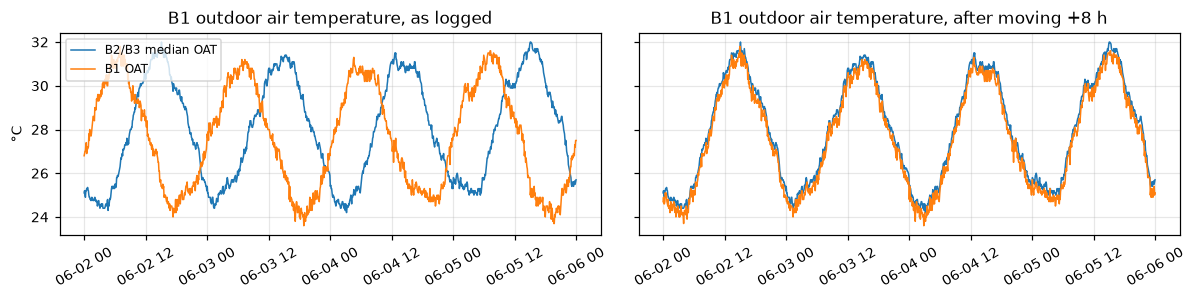

In [6]:
oat_ref = raw[raw.ahu_id.str[:2] != "B1"].groupby("timestamp").oat_c.median()
b1 = raw[raw.ahu_id == "B1-AHU-01"].set_index("timestamp").oat_c
clean = load_clean()
b1c = clean[clean.ahu_id == "B1-AHU-01"].set_index("timestamp").oat_c
win = slice("2025-06-02", "2025-06-05")
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
for a, s, title in [(ax[0], b1, "as logged"), (ax[1], b1c, "after moving +8 h")]:
    a.plot(oat_ref.loc[win], lw=1, label="B2/B3 median OAT")
    a.plot(s[~s.index.duplicated()].loc[win], lw=1, label="B1 OAT")
    a.set_title(f"B1 outdoor air temperature, {title}")
    a.tick_params(axis="x", labelrotation=30)
ax[0].set_ylabel("°C"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "clock_shift.png", dpi=170)
for name, s in [("as logged", b1), ("fixed", b1c)]:
    s = s[~s.index.duplicated()].loc["2025-06-02":"2025-06-07"]
    print(name, "mean |B1 - reference| =", round((s - oat_ref.reindex(s.index)).abs().mean(), 2), "°C")
def oat_gap(d):
    d = d[(d.ahu_id.str[:2] == "B1") & d.timestamp.between("2025-06-02", "2025-06-07 23:55")].drop_duplicates(["ahu_id", "timestamp"])
    return (d.oat_c - d.timestamp.map(oat_ref)).abs().groupby(d.ahu_id).mean()
every_b1 = pd.DataFrame({"as logged": oat_gap(raw), "fixed": oat_gap(clean)})
print(f"all {len(every_b1)} B1 AHUs, mean |B1 - reference| in °C:", every_b1.agg(["min", "max"]).round(2).to_dict())

As logged, B1's outdoor air temperature differs from the other two buildings by 3.61 °C on average over the shifted week. After moving those rows 8 hours later the gap falls to 0.33 °C, which is ordinary sensor spread. The left chart shows B1 out of step with the reference curve, the right one shows the two curves on top of each other after the fix.

In [7]:
df, log = load_clean(return_log=True)
log

,issue,building,rows,detail
0,clock shift (logger wrote UTC),B1,32153,labels 2025-06-01 16:00:00 to 2025-06-08 16:00...
1,duplicate export,B3,3439,days ['2025-02-14']; kept first copy
2,"fan power in W, not kW",B3-AHU-04,6023,2025-04-01 to 2025-04-21: divided by 1000
3,CO2 at 0 or 5000 ppm (sensor failure),B2-AHU-03,781,2025-01-20 01:00:00 to 2025-02-27 22:55:00: se...
4,sat_c frozen (flatline),B2-AHU-08,2587,2025-07-21 00:00:00 to 2025-07-29 23:55:00 at ...
5,rat_c frozen (flatline),B1-AHU-07,2239,2025-05-05 07:00:00 to 2025-05-26 19:25:00 at ...
6,logging gap,B2,0,2025-03-10 05:55:00 to 2025-03-18 14:00:00 (8 ...


The cleaning log above lists every change with its row count. The clock shift moves 32,153 rows, the W to kW fix touches 6,023 rows, and the two frozen sensors cover 2,587 (SAT, B2-AHU-08) and 2,239 (RAT, B1-AHU-07) rows, which are set to missing rather than deleted. The B2 outage in March changes no rows and is left as a gap.

Other checks came back clean. No sensor sits at its range limits apart from CO2, setpoints are constant per AHU, fan status agrees with fan speed and power, and in the test period the only missing values are CO2 and airflow where no sensor exists (30% and 70% of rows). B2-AHU-08's SAT joins them once the frozen-sensor check above sets 21 to 29 July to missing.

In [8]:
rated = raw.ahu_id.map(meta.set_index("ahu_id").fan_rated_kw)
p = raw.assign(ratio=raw.fan_power_kw / rated)
print("fan power / rating, top AHUs:")
print(p.groupby("ahu_id").ratio.max().sort_values().tail(3).round(1))
print("setpoint values per AHU:", raw.groupby("ahu_id").sat_sp_c.nunique().max())
r = raw[raw.fan_status == 1]
print("running with speed 0:", int((r.fan_speed_pct == 0).sum()), "| off with power > 0.5 kW:",
      int(((raw.fan_status == 0) & (raw.fan_power_kw > 0.5)).sum()))
off = raw[(raw.fan_status == 0) & (raw.fan_power_kw > 0.5)]
print("fan off with power > 0.5 kW, by AHU:", off.ahu_id.value_counts().to_dict(), "| from", off.timestamp.min(), "to", off.timestamp.max(),
      "| logged values:", sorted(off.fan_power_kw.unique()), "| hours:", sorted(off.timestamp.dt.hour.unique()))
print("same check after cleaning:", int(((clean.fan_status == 0) & (clean.fan_power_kw > 0.5)).sum()), "rows")

fan power / rating, top AHUs:
ahu_id
B3-AHU-02      1.0
B3-AHU-09      1.0
B3-AHU-04    471.0
Name: ratio, dtype: float64
setpoint values per AHU: 1
running with speed 0: 0 | off with power > 0.5 kW: 2501
fan off with power > 0.5 kW, by AHU: {'B3-AHU-04': 2501} | from 2025-04-01 00:00:00 to 2025-04-21 23:55:00 | logged values: [np.float32(40.0)] | hours: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(23)]
same check after cleaning: 0 rows


B3-AHU-04 reaches 471 times its rated motor power, which is impossible for a motor and exactly what readings in W instead of kW look like. The next highest units reach 1.0 times their rating, which is normal at full speed. Every AHU keeps a single setpoint value, and no unit reports running at zero speed. All 2,501 rows with the fan off but more than 0.5 kW of power belong to B3-AHU-04 from 1 to 21 April, logged at night (11 pm to 8 am) at a flat 40.0. That is the same W-for-kW error at a 40 W standby draw, and after the fix the same check finds 0 rows.

## 4. Patterns across buildings and units (January to June)

The test months are left out from here on. The next cell plots the running schedule and the valve and setpoint-error distributions by building, using January to June only.

B1 share running 10h to 16h: all days 71.5%, weekdays 95.3%, weekends 12.5%
B1 units running at 01h to 03h (share above half): {'B1-AHU-15': 1.0, 'B1-AHU-16': 1.0}
b     B1   B2   B3
h                 
3   0.12  1.0  0.0
10  0.71  1.0  1.0
20  0.12  1.0  1.0


/var/folders/4b/xlstm1l97ts2p3hsf2p40vcr0000gn/T/ipykernel_72982/1004481520.py:14: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hr, weekday = b1r.timestamp.dt.hour, b1r.timestamp.dt.dayofweek < 5


,valve p0.1,valve p0.25,valve p0.5,valve p0.75,valve p0.9,valve above 95%,|SAT - SP| below 0.3 °C
ahu_id,,,,,,,
B1,30.3,37.0,47.7,57.3,65.8,0.046,0.681
B2,28.3,32.2,40.1,51.8,60.2,0.002,0.713
B3,35.0,40.2,48.8,60.3,100.0,0.132,0.630


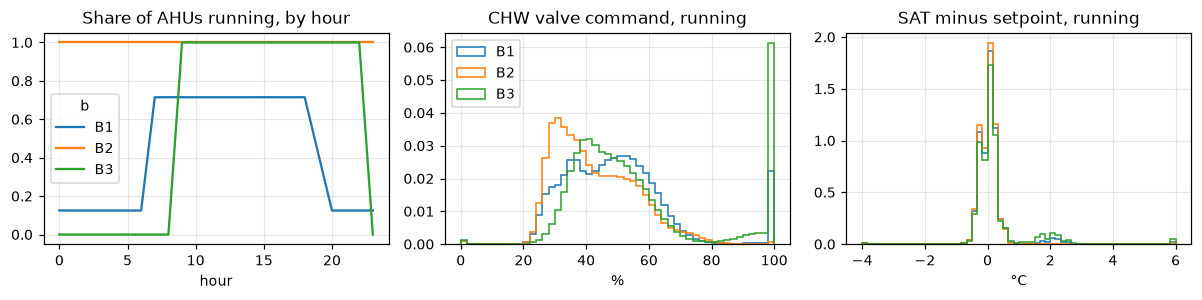

In [9]:
df = add_physics(df, meta)
trn = df[df.split == "train"]  # January to June only, the test months stay closed
run = trn[trn.steady]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
sched = trn.assign(b=trn.ahu_id.str[:2], h=trn.timestamp.dt.hour).groupby(["b", "h"]).fan_status.mean().unstack(0)
sched.plot(ax=ax[0]); ax[0].set_title("Share of AHUs running, by hour"); ax[0].set_xlabel("hour")
for b, g in run.groupby(run.ahu_id.str[:2]):
    ax[1].hist(g.chw_valve_cmd_pct, bins=50, histtype="step", density=True, label=b)
    ax[2].hist(g.sat_err.clip(-4, 6), bins=60, histtype="step", density=True, label=b)
ax[1].set_title("CHW valve command, running"); ax[1].set_xlabel("%"); ax[1].legend()
ax[2].set_title("SAT minus setpoint, running"); ax[2].set_xlabel("°C")
fig.tight_layout(); fig.savefig(FIG / "patterns.png", dpi=170)
b1r = trn[trn.ahu_id.str[:2] == "B1"]
hr, weekday = b1r.timestamp.dt.hour, b1r.timestamp.dt.dayofweek < 5
print(f"B1 share running 10h to 16h: all days {b1r.fan_status[hr.between(10, 16)].mean():.1%}, weekdays "
      f"{b1r.fan_status[hr.between(10, 16) & weekday].mean():.1%}, weekends {b1r.fan_status[hr.between(10, 16) & ~weekday].mean():.1%}")
print("B1 units running at 01h to 03h (share above half):", b1r[hr.between(1, 3)].groupby("ahu_id").fan_status.mean().loc[lambda s: s > 0.5].round(2).to_dict())
print(sched.loc[[3, 10, 20]].round(2))
bld = run.ahu_id.str[:2]
pd.concat([run.groupby(bld).chw_valve_cmd_pct.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack().add_prefix("valve p"),
           run.groupby(bld).chw_valve_cmd_pct.apply(lambda s: (s > 95).mean()).rename("valve above 95%"),
           run.sat_err.abs().lt(0.3).groupby(bld).mean().rename("|SAT - SP| below 0.3 °C")], axis=1).round(3)

The left chart shows the three schedules. B2 (hospital) runs all 24 hours, B3 (mall) runs from about 09h00 to 23h00 every day, and B1 (office) runs 71.5% of units between 10h00 and 16h00 because the curve averages in weekends (95.3% on weekdays, 12.5% at weekends), with a 12% floor at night from the two units that run around the clock. The middle chart shows the valve between 32% and 60% for the middle half of running rows (25th to 75th percentile across buildings), with a spike at 100% in B3, whose 90th percentile is already 100%, and in B1, where 4.6% of rows sit above 95%. The right chart shows SAT mostly within 0.3 °C of setpoint, with a second small hump near +2 °C in the same two buildings. The next cell traces both humps to three units.

In [10]:
lab_rows = pd.Series(False, index=run.index)
for e in labels.itertuples():
    lab_rows |= (run.ahu_id == e.ahu_id) & run.timestamp.between(e.start, e.end)
unit = run[~lab_rows & (run.split == "train")].groupby("ahu_id").agg(
    valve_at_100=("chw_valve_cmd_pct", lambda s: (s > 95).mean()), sat_err=("sat_err", "median"),
    fan=("fan_speed_pct", "median"), static_err=("static_err", "median"), filter_max=("filter_dp_pa", "max"))
unit.round(2).sort_values("valve_at_100", ascending=False).head(8)

,valve_at_100,sat_err,fan,static_err,filter_max
ahu_id,,,,,
B1-AHU-05,0.84,1.9,99.500000,-34.0,262.0
B3-AHU-09,0.78,1.9,98.800003,-18.0,269.0
B3-AHU-02,0.73,1.5,98.699997,-15.0,266.0
B1-AHU-01,0.00,0.0,72.400002,0.0,178.0
B3-AHU-03,0.00,0.0,69.199997,0.0,231.0
B2-AHU-08,0.00,0.0,54.599998,0.0,169.0
B2-AHU-09,0.00,0.0,47.599998,0.0,123.0
B2-AHU-10,0.00,0.0,62.000000,0.0,252.0


Three units run flat out all the time, *outside* any labelled event (B1-AHU-05, B3-AHU-02 and B3-AHU-09). Their valve is above 95% for 73% to 84% of running time, the fan runs near 99%, and SAT still sits 1.5 to 1.9 °C above setpoint. The next unit in the table never opens its valve past 95%. That is an undersized or chronically degraded unit (fouled coil or low CHW flow, while the next cell rules out the filter), not a model artefact. These go on the client checklist. They also matter for modelling, because a "low coil capacity" fault on a unit whose valve is already at 100% cannot show up as more valve opening.

B1-AHU-05: filter change 2025-06-30, 244 to 92 Pa; valve above 95% 84% before, 85% after (144 running rows after)
B3-AHU-02: filter change 2025-04-26, 255 to 94 Pa; valve above 95% 72% before, 75% after (9002 running rows after)
B3-AHU-09: filter change 2025-05-24, 246 to 108 Pa; valve above 95% 77% before, 80% after (6136 running rows after)


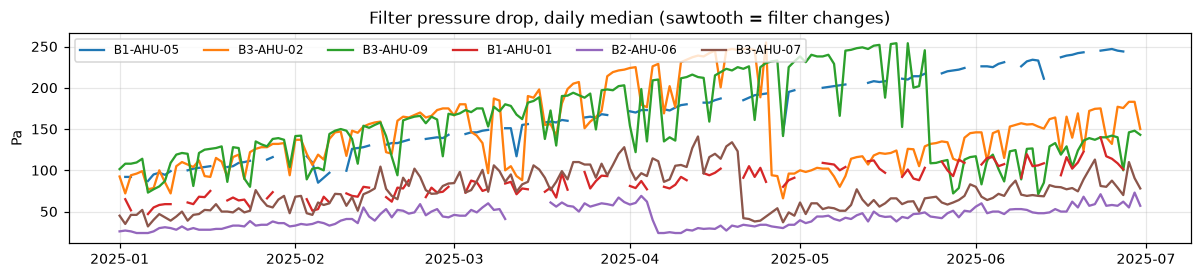

In [11]:
fig, ax = plt.subplots(figsize=(11, 2.6))
for a in ["B1-AHU-05", "B3-AHU-02", "B3-AHU-09", "B1-AHU-01", "B2-AHU-06", "B3-AHU-07"]:
    s = trn[(trn.ahu_id == a) & trn.steady].set_index("timestamp").filter_dp_pa.resample("1D").median()
    ax.plot(s, label=a)
ax.set_title("Filter pressure drop, daily median (sawtooth = filter changes)"); ax.set_ylabel("Pa"); ax.legend(ncol=6, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "filter_dp.png", dpi=170)
for a in ["B1-AHU-05", "B3-AHU-02", "B3-AHU-09"]:
    g = run[~lab_rows & (run.ahu_id == a)].set_index("timestamp")
    daily = g.filter_dp_pa.resample("1D").median().dropna()
    d = daily.diff().idxmin()  # the largest one-day fall is the filter change
    print(f"{a}: filter change {d.date()}, {daily.shift().loc[d]:.0f} to {daily.loc[d]:.0f} Pa; valve above 95% "
          f"{(g.chw_valve_cmd_pct[:d - pd.Timedelta('1s')] > 95).mean():.0%} before, {(g.chw_valve_cmd_pct[d:] > 95).mean():.0%} after "
          f"({g[d:].shape[0]} running rows after)")

Filter pressure drop follows a sawtooth. B3-AHU-07 drops from about 135 to 40 Pa in late April and B2-AHU-06 from about 65 to 25 Pa in early April, which are filter changes. B1-AHU-05 climbs from about 90 to 245 Pa from January and is changed only on 30 June (244 to 92 Pa). The three saturated units all get a filter change, and it does not end their saturation. The valve sits above 95% for 84%, 72% and 77% of running time before the change (B1-AHU-05, B3-AHU-02, B3-AHU-09) and 85%, 75% and 80% after, so a dirty filter is not the cause. For B1-AHU-05 only 144 running rows follow the change, so its after figure is thin. Filter loading is normal ageing, not a labelled fault, so the normal-behaviour models take filter pressure drop into account instead of flagging it.

## 5. Fault signatures, physics vs labels

For each labelled event the table takes the median of each signal during the event minus the same AHU's median over the 7 days before it (steady running rows only), then the median of that change per fault type.

In [12]:
SIG = {"sat_err": "SAT − SP (°C)", "chw_valve_cmd_pct": "valve (%)", "coil_dt": "coil ΔT (°C)",
       "oaf": "OA fraction", "mix_dt": "MAT − RAT (°C)", "oa_damper_cmd_pct": "damper cmd (%)",
       "co2_ppm": "CO2 (ppm)", "fan_speed_pct": "fan (%)", "static_err": "static err (Pa)"}
rows = []
for e in labels.itertuples():
    g = run[run.ahu_id == e.ahu_id]
    during = g[g.timestamp.between(e.start, e.end)][list(SIG)].median()
    before = g[g.timestamp.between(e.start - pd.Timedelta("7D"), e.start - pd.Timedelta("1D"))][list(SIG)].median()
    rows.append((during - before).rename(f"{e.ahu_id} {e.fault_type}").to_frame().T.assign(fault=e.fault_type))
delta = pd.concat(rows)
sig = delta.groupby("fault")[list(SIG)].median().rename(columns=SIG)
sig.round(2)

,SAT − SP (°C),valve (%),coil ΔT (°C),OA fraction,MAT − RAT (°C),damper cmd (%),CO2 (ppm),fan (%),static err (Pa)
fault,,,,,,,,,
chw_valve_stuck,5.8,19.60,-4.10,0.00,-0.15,0.0,-24.75,15.40,-76.5
low_coil_capacity,0.1,11.45,-0.20,0.00,0.00,0.0,-4.00,0.10,-1.0
oa_damper_stuck,0.0,-0.65,-0.50,-0.11,-0.60,40.0,586.00,0.20,0.0
sat_sensor_bias,0.0,0.65,0.05,0.00,0.00,0.0,40.00,3.05,0.0


Each fault moves a different set of signals. Stuck valves move the most (SAT +5.8 °C, valve +19.6%, coil ΔT −4.1 °C, fan +15.4%). Stuck dampers have their own signature (OA fraction −0.11, damper command +40%, CO2 +586 ppm). Low coil capacity mostly moves the valve (+11.5%) with SAT almost on setpoint (+0.1 °C). Sensor bias barely moves any median (fan +3.1%, CO2 +40 ppm), which makes it the hardest fault to see. Two cautions apply to these medians. The stuck-valve figures mix stuck-open and stuck-closed events, which move in opposite directions (see the per-event table below), so +5.8 °C describes neither group well. The damper figures for CO2 come from B1 and B2 only, because B3 has no CO2 sensor, so in the mall a stuck damper shows only through the outdoor-air fraction and the mixed-air temperature.

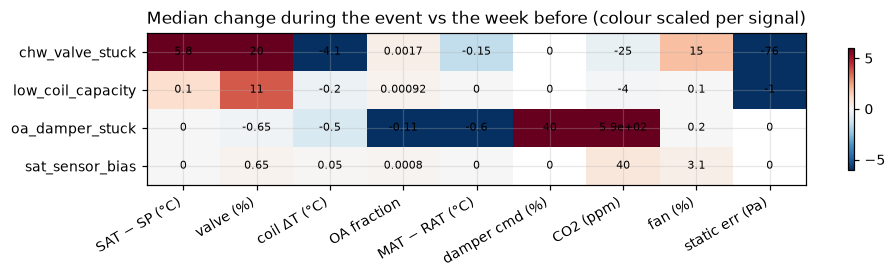

In [13]:
z = sig / delta[list(SIG)].abs().median().values
fig, ax = plt.subplots(figsize=(9, 2.6))
hm = ax.imshow(z.clip(-6, 6), cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
ax.set_xticks(range(len(SIG))); ax.set_xticklabels(SIG.values(), rotation=30, ha="right")
ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = sig.iloc[i, j]
        if pd.notna(v): ax.text(j, i, f"{v:.2g}", ha="center", va="center", fontsize=7)
ax.set_title("Median change during the event vs the week before (colour scaled per signal)")
fig.colorbar(hm, ax=ax, shrink=0.8); fig.tight_layout(); fig.savefig(FIG / "fault_signatures.png", dpi=170)

The heat map shows the same table with each signal scaled to its own typical change, so small but consistent moves such as the 0.11 drop in OA fraction stand out as clearly as the 586 ppm rise in CO2. Every fault except sensor bias has at least one signal coloured at the edge of the scale.

In [14]:
delta.round(2).sort_values("fault")

,sat_err,chw_valve_cmd_pct,coil_dt,oaf,mix_dt,oa_damper_cmd_pct,co2_ppm,fan_speed_pct,static_err,fault
B1-AHU-06 chw_valve_stuck,12.10,39.20,-7.90,0.01,-0.30,0.0,-74.0,29.80,-97.0,chw_valve_stuck
B3-AHU-09 chw_valve_stuck,3.90,0.00,-2.40,-0.00,-0.10,0.0,NaN,1.00,-69.0,chw_valve_stuck
B1-AHU-04 chw_valve_stuck,-5.60,-51.30,5.60,0.01,0.00,0.0,96.0,-25.40,0.0,chw_valve_stuck
B3-AHU-06 chw_valve_stuck,10.70,45.00,-7.60,-0.00,-0.40,0.0,NaN,38.30,-111.0,chw_valve_stuck
B2-AHU-08 chw_valve_stuck,11.00,55.00,-8.40,-0.01,-0.20,-1.3,-113.0,46.55,-93.0,chw_valve_stuck
B3-AHU-03 chw_valve_stuck,7.70,47.20,-5.80,0.01,-0.20,0.0,NaN,31.30,-84.0,chw_valve_stuck
B3-AHU-10 chw_valve_stuck,-4.50,-38.60,4.00,-0.00,0.10,0.0,NaN,-8.65,0.0,chw_valve_stuck
B2-AHU-10 chw_valve_stuck,-4.90,-54.30,3.40,0.01,0.10,0.0,24.5,-18.60,0.0,chw_valve_stuck
B1-AHU-07 low_coil_capacity,0.10,31.65,-0.10,-0.00,0.10,0.0,-25.0,0.15,-1.0,low_coil_capacity
B2-AHU-04 low_coil_capacity,0.10,8.45,-0.00,0.00,0.10,-0.4,-7.0,-1.65,0.0,low_coil_capacity


Per event, stuck valves go both ways. Three events (B1-AHU-04, B2-AHU-10, B3-AHU-10) show SAT 4.5 to 5.6 °C *below* setpoint with the valve closing by 39% to 54% (stuck open), while the other five show SAT 3.9 to 12.1 °C above setpoint (stuck closed). The classifier therefore needs the sign as well as the size of the change. On the saturated units B1-AHU-05, B3-AHU-02 and B3-AHU-09 the valve change is 0 because it already sits at 100%, and the fault only shows as SAT rising. On those units low coil capacity therefore looks like a stuck-closed valve (B3-AHU-02 shows SAT +5.5 °C with no valve change, B1-AHU-05 SAT +2.65 °C), and the classifier can mix up the two classes there, which section 13 confirms. The damper fault on B3-AHU-05 has a damper command change of 0 and no CO2, so its only trace is the outdoor-air fraction (−0.10). Sensor bias moves the fan by 8% to 20% per event, but in both directions, which is why its median is small.

## 6. Question register and what this EDA can claim

The brief fixed some questions before any data was seen. Others came up while looking at the data. Keeping them apart
shows which findings were looked for and which were found, because a pattern found by searching is a lead to test, not a result.

| Question | Set by | Answered in | Finding |
|---|---|---|---|
| Is the data complete and trustworthy? | Brief (Q1) | Sections 2 and 3 | 98.25% (train) and 99.7% (test) of expected rows, six issues fixed or masked |
| What would I ask the client to check? | Brief (Q1) | Section 3, report Q1 | Logger clocks, B3-AHU-04 power units, frozen sensors on B2-AHU-08 and B1-AHU-07 |
| How do the buildings and units differ? | Brief (Q1) | Section 4 | Three schedules, three units always at full valve |
| What does each fault do to the signals? | Brief (Q1) | Section 5 | Each type moves its own set of signals |
| Are there faults with no label? | Emerged in section 4 | Sections 13 and 16 | One unlabelled stuck damper in April, three test-period leads |
| Are some units always saturated? | Emerged in section 4 | Sections 4 and 13 | B1-AHU-05, B3-AHU-02 and B3-AHU-09, half of the model's errors |
| Does filter loading look like a fault? | Emerged in section 4 | Section 4 | Sawtooth with replacements, not a labelled fault, kept out of the features |
| Do stuck valves always push SAT up? | Emerged in section 5 | Section 5 | No, three events go below setpoint, so the model needs both directions |

**Correlation is not cause.** Every link in sections 1 to 6 is an association. The fault signatures in section 5 agree with the
physics in the brief, which makes them believable, but the data alone does not prove that a fault caused each move. The test-period
leads in section 16 especially are hypotheses for a technician to check on site, and a confirmed visit is the only way to turn
one into a label.

## 7. Modelling approach

**Framing.** The maintenance team wants three things. Is there a fault, which one is it, and how can wasted
visits be kept to a minimum? Only 28 labelled events exist, the labels are incomplete (they come from work orders), and each
AHU has its own normal operating point. The model therefore has three layers, each doing one job.

1. **Physics features** per row (setpoint error, outdoor-air fraction, coil ΔT, fan power against the affinity law).
2. **Normal-behaviour models.** Gradient-boosted regressors are fit on rows with no work order, one per
   signal for the whole fleet, with the AHU as a categorical input. They predict what valve, fan, mixed air,
   damper, CO2 and return air *should* be, and the residual is the fault evidence. This absorbs unit-to-unit differences
   and lets the approach run on a new AHU, though a brand-new unit needs about two weeks of history first (section 14).
3. **A classifier on trailing windows** (3 h and 12 h medians of residuals and physics features) that
   outputs P(normal) and P(each fault). Windows only look backwards, so the same code runs live.

A causal **alarm state machine** turns probabilities into alarms. An alarm opens when the smoothed P(fault)
crosses a threshold and closes only after a sustained quiet period. Its type is the class with the highest
mean probability since the alarm opened, so the type does not flicker.

Pure rules would need separate thresholds for each of the 40 units, and a pure classifier on raw signals would
learn unit identity instead of faults. The hybrid keeps the physics explainable and lets the data set the thresholds.

The next cell frees the exploration frames and rebuilds the modelling frame from the raw log. It applies the same
cleaning functions as section 3, adds the physics features and the labels, and blanks the labels of July and August.

In [15]:
del raw, clean_df, run_rows, run, trn
df, labels, log_model = PL.build_frame()
print(f"{len(df):,} rows, cleaning log identical to section 3: {log_model.equals(log)}, "
      f"labelled rows {df.label.notna().sum():,}, test rows without label {df.label.isna().sum():,}")

2,762,088 rows, cleaning log identical to section 3: True, labelled rows 2,050,094, test rows without label 711,994


The model frame has 2,762,088 rows, the same as the cleaned data, and its cleaning log is identical to the one in section 3, so the modelling half starts from exactly the data the EDA checked. Of these rows, 2,050,094 are January to June with labels and 711,994 are July and August without labels, which is the size the predictions file must have.

## 8. Normal-behaviour residuals (out of fold)

For train month *k*, the normal models are fit on every other month, minus a 2-day purge around
month *k* and minus any event that touches it. The test period uses models fit on all of January to June.

In [16]:
res = PL.residuals(df, labels)
w = PL.make_windows(df, res)
cols = F.feature_columns(w)
print(len(w), "steady running rows,", len(cols), "features")
clean = w[(w.split == "train") & (w.label == "normal") & ~w.near_event]
mae = {c: clean[c].abs().median() for c in F.RESID.values()}
by_class = w[w.split == "train"].groupby("label")[list(F.RESID.values())].median().round(2)
pd.Series(mae, name="median |residual| on normal rows").round(2).to_frame().T

1752625 steady running rows, 38 features


,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
median |residual| on normal rows,1.71,1.77,0.14,0.0,14.35,0.1


There are 1,752,625 steady running rows from January to August, and the classifier built on them uses 38 features. The normal models learn only from January to June rows with no work order and at least a day away from any event. On normal rows the typical miss is 1.71 percentage points for the valve, 1.77 for fan power, 0.14 °C for mixed air and 14 ppm for CO2, which is small against the fault signatures in the next table. The damper residual has a median of exactly zero on normal rows, so any sustained non-zero value is already unusual.

In [17]:
R = list(F.RESID.values())
trw = w[w.split == "train"]
band = trw[(trw.label == "normal") & ~trw.near_event][R].quantile([0.01, 0.99])
outside = trw[trw.label != "normal"].groupby("label")[R].apply(lambda d: ((d < band.loc[0.01]) | (d > band.loc[0.99])).mean())
print("1% to 99% band of each residual on clean normal rows, then the share of fault rows outside it")
display(band.round(2), outside.round(2))
by_class  # median residual by true label: the faults move exactly the residuals the physics predicts

1% to 99% band of each residual on clean normal rows, then the share of fault rows outside it


,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
0.01,-6.15,-9.22,-0.49,-1.78,-52.25,-0.37
0.99,6.17,9.41,0.49,4.40,101.15,0.42


,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
label,,,,,,
chw_valve_stuck,0.95,0.79,0.48,0.03,0.26,0.83
low_coil_capacity,0.74,0.08,0.06,0.08,0.03,0.17
oa_damper_stuck,0.07,0.04,0.56,0.65,0.67,0.07
sat_sensor_bias,0.77,0.69,0.02,0.00,0.00,0.07


,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
label,,,,,,
chw_valve_stuck,15.55,22.23,0.35,0.0,-16.95,1.73
low_coil_capacity,16.64,0.37,0.02,0.0,4.29,0.04
normal,0.00,0.01,-0.00,0.0,1.03,0.00
oa_damper_stuck,-1.52,-0.04,-0.54,40.0,577.80,-0.00
sat_sensor_bias,-6.58,8.18,-0.01,0.0,43.65,-0.00


Each fault moves the residuals the physics predicts, while normal rows sit at zero. A stuck valve leaves the valve 15.6 points off its expected position and pushes fan power 22.2 points up. Low coil capacity also pushes the valve 16.6 points open, but leaves the fan almost untouched (0.37), which is what separates the two. A stuck damper is the clearest case, with the damper residual at 40 and CO2 578 ppm above normal. Sensor bias is the subtlest, with the valve 6.6 points below expected and CO2 44 ppm high, which is why it is the slowest fault to confirm. The first table, the share of fault rows outside the 1% to 99% band of normal rows, says the same thing row by row. Stuck-valve rows leave the band on the valve 95% of the time, on RAT 83% and on the fan 79%. Low coil capacity leaves it on the valve 74% of the time but on the fan only 8%. Damper faults leave it on CO2 67%, the damper 65% and MAT 56%, and sensor bias on the valve 77% and the fan 69%. Each fault therefore has its own pair of residuals that it pushes out of the band, which is the evidence the classifier types it from.

## 9. Validation scheme

* **Across time.** Leave-one-month-out on January to June with a 2-day purge, so neither the normal models nor
  the classifier see the scored month. Rolling windows are trailing only.
* **Across events.** An event that spans two months is removed from training in both folds.
* **Fuzzy edges.** Rows within 1 day of a labelled event that are not inside it are not used as
  "normal" for training, because start and end are estimates.
* **Metric from the maintenance team's view.** I count events found, events found with the right type, median
  delay from start to first alarm, and false alarms per AHU-month (an alarm run that touches no labelled
  event). Row-level accuracy is not reported, because the 95% normal rows dominate it.

Post-processing is tuned on the out-of-fold probabilities with
`J = typed recall − 4 × false alarms per AHU-month`.

In [18]:
oof = PL.oof_probabilities(w, df, labels, cols)
tr = w[w.split == "train"]; keys = tr[["ahu_id", "timestamp"]]
AHU_MONTHS = 40 * 6

grid = []
for t_on in [0.6, 0.7, 0.8, 0.9]:
    for smooth in [12, 36]:
        for hold in [36, 144]:
            s, _, _ = E.score_events(keys, E.alarms(oof, keys, t_on, 0.3, smooth, hold), labels, AHU_MONTHS)
            grid.append(dict(t_on=t_on, smooth=smooth, hold=hold, **s, J=E.objective(s)))
grid = pd.DataFrame(grid).sort_values("J", ascending=False)
grid[["t_on", "smooth", "hold", "detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month", "J"]].round(3).head(8)

,t_on,smooth,hold,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month,J
8,0.8,12,36,27,22,9.333,2,0.008,0.752
9,0.8,12,144,27,22,9.333,2,0.008,0.752
4,0.7,12,36,27,22,8.833,3,0.012,0.736
5,0.7,12,144,27,22,8.833,3,0.012,0.736
2,0.6,36,36,27,21,11.750,1,0.004,0.733
3,0.6,36,144,27,21,11.750,1,0.004,0.733
6,0.7,36,36,27,21,12.250,1,0.004,0.733
7,0.7,36,144,27,21,12.250,1,0.004,0.733


The top of the table is flat. Thresholds 0.7 and 0.8 with 1-hour smoothing find the same 27 events with the same
22 correct types, and the hold time makes no difference. The 0.8 threshold has one false alarm fewer, while longer smoothing
costs a type and about 3 hours of delay. I use `t_on=0.8, t_off=0.3, smooth=12, hold=144` (`pipeline.POST`).
The longer hold is chosen for production because it keeps one fault from re-opening several tickets.

## 10. Results (out of fold, January to June)

In [19]:
pred = E.alarms(oof, keys, **PL.POST)
summary, ev, al = E.score_events(keys, pred, labels, AHU_MONTHS)
pd.Series(summary).round(3)

events              28.000
detected            27.000
type_ok             22.000
recall               0.964
typed_recall         0.786
median_delay_h       9.333
alarms              33.000
false_alarms         2.000
fa_per_ahu_month     0.008
dtype: float64

Out of fold, the model finds 27 of 28 labelled events (96%) and gives the right type for 22 (79%). Median delay from the labelled start to the first alarm is 9.3 hours. It opens 33 alarms in total, and only 2 of them touch no labelled event, which is 0.008 false alarms per AHU-month, or about one false visit per AHU every 10 years. These thresholds were picked on the same months they are scored on, so this is the optimistic figure. The honest estimate, with thresholds picked inside each fold, is in section 12 (21 right types, 10.0 hours and 3 false alarms as shipped).

In [20]:
ev["pred_type"] = ev.pred_type.fillna("missed")
pd.crosstab(ev.fault_type, ev.pred_type, margins=True)

pred_type,chw_valve_stuck,low_coil_capacity,missed,oa_damper_stuck,sat_sensor_bias,All
fault_type,,,,,,
chw_valve_stuck,7,0,0,0,1,8
low_coil_capacity,1,5,0,0,1,7
oa_damper_stuck,0,0,1,6,0,7
sat_sensor_bias,1,1,0,0,4,6
All,9,6,1,6,6,28


The diagonal holds 22 of the 28 events. Stuck valves are the cleanest (7 of 8 right), and the damper fault is never confused with anything, though one of the 7 is missed. Sensor bias is the hardest, with 4 of 6 right and the other two called a stuck valve and low coil capacity. Low coil capacity loses one event each to a stuck valve and to sensor bias.

In [21]:
ev.groupby("fault_type").agg(events=("detected", "size"), detected=("detected", "sum"),
                             type_ok=("type_ok", "sum"), median_delay_h=("delay_h", "median")).round(1)

,events,detected,type_ok,median_delay_h
fault_type,,,,
chw_valve_stuck,8,8,7,2.0
low_coil_capacity,7,7,5,20.2
oa_damper_stuck,7,6,6,2.5
sat_sensor_bias,6,6,4,31.1


Speed depends on the fault. Stuck valves and damper faults are caught in a median of 2.0 and 2.5 hours, because they move the valve or the outdoor-air fraction at once. Low coil capacity (20.2 hours) and sensor bias (31.1 hours) build up slowly and need the 12-hour windows to show, which is acceptable for faults that waste energy over days rather than break comfort within hours.

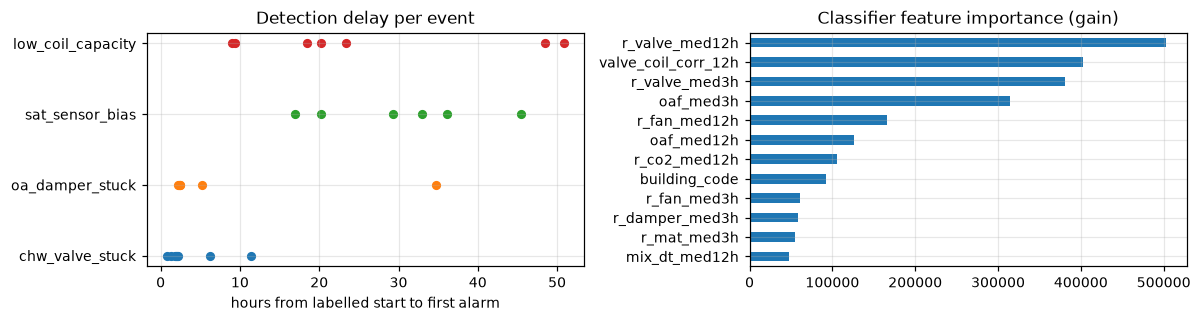

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for f in FAULTS:
    d = ev[(ev.fault_type == f) & ev.detected].delay_h
    ax[0].scatter(d, [f] * len(d), s=25)
ax[0].set_xlabel("hours from labelled start to first alarm"); ax[0].set_title("Detection delay per event")
imp = pd.Series(PL.fit_classifier(tr[cols], tr.label).booster_.feature_importance("gain"), index=cols)
imp.sort_values().tail(12).plot.barh(ax=ax[1]); ax[1].set_title("Classifier feature importance (gain)")
fig.tight_layout(); fig.savefig(FIG / "results.png", dpi=170)

The left chart shows the same split. All stuck-valve events and five of the six found damper events are caught within 12 hours, while the slow faults spread from 9 to 51 hours, with two low-coil-capacity events near 50 hours. Of the 27 found events, 20 are caught within a day. The right chart shows the classifier leans on the valve residual (3 h and 12 h), the valve-to-coil correlation and the outdoor-air fraction, which are exactly the physical signatures from section 5. The building code is only eighth, so the model is not just learning which building it is looking at.

## 11. Is the model better than the simple alternatives?

Three simpler methods go through the same alarm logic and the same event scorer. The first is the supply-air temperature alarm most building management systems already have. The second is a set of fleet-wide engineering rules, one per fault (`ahu_fdd/baseline.py`). The third is the simplest machine-learning model, a multinomial logistic regression on the same 38 features, training rows and class weights as the LightGBM classifier, with its imputer, scaler and encoder fit inside each fold. It is scored out of fold like the model, and its alarm settings are tuned on the same grid, so it gets the same advantage as the model. The rule thresholds were picked on January to June itself, so this comparison flatters the rules, because the model is scored out of fold.

In [23]:
from ahu_fdd import baseline as B
oof_lr = PL.oof_probabilities(w, df, labels, cols, fit=B.fit_logistic)
lr_grid = pd.DataFrame([dict(t_on=t, smooth=s, hold=h, J=E.objective(E.score_events(
    keys, E.alarms(oof_lr, keys, t, 0.3, s, h), labels, AHU_MONTHS)[0])) for t, s, h in
    [(t, s, h) for t in [0.6, 0.7, 0.8, 0.9] for s in [12, 36] for h in [36, 144]]])
best = lr_grid.loc[lr_grid.J.idxmax()]
LR_POST = dict(t_on=float(best.t_on), t_off=0.3, smooth=int(best.smooth), hold=int(best.hold))
print("logistic regression, best alarm settings on the same grid:", LR_POST)
methods = {"BMS SAT alarm (today)": B.bms_alarm(tr), "Expert rules": B.expert_rules(tr),
           "Logistic regression": oof_lr, "Model": oof}
scored = {}
for name, p in methods.items():
    s, e, _ = E.score_events(keys, E.alarms(p, keys, **(LR_POST if name == "Logistic regression" else PL.POST)), labels, AHU_MONTHS)
    scored[name] = (s, e)
cmp_base = pd.DataFrame({k: v[0] for k, v in scored.items()}).T
cmp_base = cmp_base[["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]].astype(float)
cmp_base.loc["BMS SAT alarm (today)", "type_ok"] = np.nan  # it never names a fault
cmp_base.round(4)

logistic regression, best alarm settings on the same grid: {'t_on': 0.9, 't_off': 0.3, 'smooth': 36, 'hold': 144}


,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month
BMS SAT alarm (today),14.0,NaN,2.8750,8.0,0.0333
Expert rules,19.0,10.0,2.5833,9.0,0.0375
Logistic regression,25.0,17.0,6.8333,27.0,0.1125
Model,27.0,22.0,9.3333,2.0,0.0083


The logistic regression tunes itself to the strictest setting on the grid (threshold 0.9, 36-step smoothing, 144-step hold) and still raises 27 false alarms, 0.112 per AHU-month, against 2 (0.008) for the model. It finds 25 events and names 17, which beats the expert rules (19 found, 10 named) but trails the model (27 found, 22 named). Its median delay of 6.8 hours is shorter than the model's 9.3 hours, but that comes with more than ten times as many false alarms. The BMS alarm finds 14 events with 8 false alarms. The same residual and window features therefore carry most of the signal, and the tree model adds what a linear boundary cannot, which is telling a fault apart from normal operating swings without flooding the team.

In [24]:
def with_ci(s, e):
    n = s["events"]
    d, t = E.proportion_ci(s["detected"], n), E.proportion_ci(s["type_ok"], n)
    m, f = E.median_ci(e.delay_h), E.rate_ci(s["false_alarms"], AHU_MONTHS)
    return {"found": f"{s['detected']}/{n} ({d[0]:.0%} to {d[1]:.0%})",
            "right type": f"{s['type_ok']}/{n} ({t[0]:.0%} to {t[1]:.0%})",
            "median delay h": f"{s['median_delay_h']:.1f} ({m[0]:.1f} to {m[1]:.1f})",
            "false alarms per AHU-month": f"{s['fa_per_ahu_month']:.4f} ({f[0]:.3f} to {f[1]:.3f})"}
pd.DataFrame({k: with_ci(*scored[k]) for k in ["Model", "Logistic regression", "Expert rules"]}).T

,found,right type,median delay h,false alarms per AHU-month
Model,27/28 (82% to 100%),22/28 (59% to 92%),9.3 (2.5 to 20.2),0.0083 (0.001 to 0.030)
Logistic regression,25/28 (72% to 98%),17/28 (41% to 78%),6.8 (4.1 to 17.4),0.1125 (0.074 to 0.164)
Expert rules,19/28 (48% to 84%),10/28 (19% to 56%),2.6 (2.2 to 3.4),0.0375 (0.017 to 0.071)


The intervals are wide because there are only 28 events. The model finds 27 of 28 (82% to 100%) and names 22 (59% to 92%), the logistic regression finds 25 (72% to 98%) and names 17 (41% to 78%), and the rules find 19 (48% to 84%) and name 10 (19% to 56%). The false-alarm intervals do not overlap, 0.0083 per AHU-month for the model (0.001 to 0.030) against 0.1125 for the logistic regression (0.074 to 0.164), while the rules (0.0375, 0.017 to 0.071) overlap the model only at the edge. On false alarms the model is clearly ahead, while on typing the model and the logistic regression overlap, which the paired test below checks directly.

In [25]:
m_ev, r_ev = scored["Model"][1], scored["Expert rules"][1]
both = m_ev.detected & r_ev.detected
paired = pd.DataFrame({
    "found": E.mcnemar_exact(m_ev.detected, r_ev.detected),
    "right type": E.mcnemar_exact(m_ev.type_ok, r_ev.type_ok)}).T
print("median delay on the", int(both.sum()), "events both methods find:",
      m_ev.delay_h[both].median().round(1), "h (model) vs", r_ev.delay_h[both].median().round(1), "h (rules)")
paired

median delay on the 19 events both methods find: 2.5 h (model) vs 2.6 h (rules)


,only_first,only_second,p_value
found,8.0,0.0,0.007812
right type,12.0,0.0,0.000488


Comparing the two methods event by event removes the luck of which events happen to exist. On the 19 events both methods find, the median delay is the same (2.5 hours for the model, 2.6 for the rules), so the model is not slower on the faults the rules can see. The model's longer overall median comes from the 8 extra faults that only the model finds. The model finds 8 events the rules miss and the rules find none the model misses (exact McNemar p = 0.008). For the right type the split is 12 to 0 (p = 0.0005). Both gaps are well beyond chance.

In [26]:
seed_rows = []
for seed in range(5):  # seed 0 is the run above; the residual models stay fixed
    p = oof if seed == 0 else PL.oof_probabilities(w, df, labels, cols, seed=seed)
    s, _, _ = E.score_events(keys, E.alarms(p, keys, **PL.POST), labels, AHU_MONTHS)
    seed_rows.append(dict(seed=seed, **s))
seeds = pd.DataFrame(seed_rows).set_index("seed")[["detected", "type_ok", "median_delay_h", "false_alarms"]]
json.dump({"baselines": {k: {m: float(x) for m, x in v[0].items()} for k, v in scored.items()},
           "seeds": seeds.reset_index().to_dict("records")},
          open(CODE_DIR / "outputs" / "baselines_and_seeds.json", "w"), indent=1, default=float)
pd.concat([seeds, seeds.agg(["mean", "std"]).round(2)])

,detected,type_ok,median_delay_h,false_alarms
0,27.0,22.00,9.333333,2.00
1,27.0,21.00,10.666667,3.00
2,27.0,21.00,11.000000,3.00
3,27.0,21.00,8.833333,3.00
4,27.0,21.00,10.916667,3.00
mean,27.0,21.20,10.150000,2.80
std,0.0,0.45,1.000000,0.45


Retraining the classifier with five different random seeds barely moves the result. Every seed finds 27 of 28 events. Typing is 22 for seed 0 and 21 for the other four (mean 21.2, standard deviation 0.45), median delay ranges from 8.8 to 11.0 hours (mean 10.2), and false alarms are 2 or 3 (mean 2.8). The reported seed-0 run is therefore on the good side of the spread by about one typed event and one false alarm, and the honest summary is "21 to 22 typed, 2 to 3 false alarms".

## 12. Honest estimate, several comparisons and calibration

The post-processing in section 9 was tuned on the same six months it is scored on, which flatters the result a little.
The next cell repeats the tuning inside the folds (nested), so each month is scored with settings chosen on the other
five months only.

In [27]:
GRID = [(t, s, h) for t in [0.6, 0.7, 0.8, 0.9] for s in [12, 36] for h in [36, 144]]
month = tr.timestamp.dt.month
pred_by = {g: E.alarms(oof, keys, g[0], 0.3, g[1], g[2]) for g in GRID}
def nest(grid):
    out, picked = pd.Series("normal", index=tr.index, dtype=object), {}
    for k in range(1, 7):
        inner = month != k  # tune on the other five months only
        J = {g: E.objective(E.score_events(keys[inner], pred_by[g][inner], labels, 40 * 5)[0]) for g in grid}
        picked[k] = max(J, key=J.get)
        out[month == k] = pred_by[picked[k]][month == k]
    return out, picked
nested_pred, chosen = nest(GRID)
nested, nested_ev, _ = E.score_events(keys, nested_pred, labels, AHU_MONTHS)
pred_144, chosen_144 = nest([g for g in GRID if g[2] == 144])
nested_144 = E.score_events(keys, pred_144, labels, AHU_MONTHS)[0]
print("chosen (t_on, smooth, hold) per held-out month:", chosen)
print("same, with the hold fixed at 144 steps (12 h) as in production:", chosen_144)
pd.DataFrame({"tuned in sample": summary, "nested (honest)": nested, "nested, 12-hour hold": nested_144}).loc[
    ["detected", "type_ok", "median_delay_h", "alarms", "false_alarms", "fa_per_ahu_month"]].astype(float).round(4)

chosen (t_on, smooth, hold) per held-out month: {1: (0.6, 36, 36), 2: (0.8, 12, 36), 3: (0.8, 12, 36), 4: (0.8, 12, 36), 5: (0.9, 36, 36), 6: (0.8, 12, 36)}
same, with the hold fixed at 144 steps (12 h) as in production: {1: (0.6, 36, 144), 2: (0.8, 12, 144), 3: (0.8, 12, 144), 4: (0.8, 12, 144), 5: (0.7, 12, 144), 6: (0.8, 12, 144)}


,tuned in sample,nested (honest),"nested, 12-hour hold"
detected,27.0000,27.0000,27.0000
type_ok,22.0000,20.0000,21.0000
median_delay_h,9.3333,11.2500,10.0000
alarms,33.0000,36.0000,34.0000
false_alarms,2.0000,2.0000,3.0000
fa_per_ahu_month,0.0083,0.0083,0.0125


Tuned honestly, the model still finds 27 of 28 events with 2 false alarms (0.008 per AHU-month), but the right
type drops from 22 to 20 (71%, 95% interval 51% to 87%) and the median delay rises from 9.3 to 11.3 hours. Four of the six
months pick a 0.8 threshold with 1-hour smoothing, January picks 0.6 and May picks 0.9. Every month picks the 3-hour hold,
because the hold barely changes `J`. Production keeps the 12-hour hold so that one fault does not reopen several tickets.
With the hold fixed at 12 hours, as shipped, the folds pick 0.8 with 1-hour smoothing in four months, 0.6 with 3-hour smoothing in January and 0.7 in May. That run finds 27, types 21 (75%, 95% interval 55% to 89%), has a median delay of 10.0 hours and raises 3 false alarms (0.0125 per AHU-month). The last column is the configuration behind `predictions.csv`, so it is the headline the report quotes.

The report makes four event-by-event claims against the simpler methods. Testing four claims raises the chance
that one of them passes by luck, so the next cell applies the Holm correction to the exact McNemar p-values.

In [28]:
b_ev = scored["BMS SAT alarm (today)"][1]
family = {"model vs rules, found": E.mcnemar_exact(m_ev.detected, r_ev.detected),
          "model vs rules, right type": E.mcnemar_exact(m_ev.type_ok, r_ev.type_ok),
          "model vs BMS alarm, found": E.mcnemar_exact(m_ev.detected, b_ev.detected),
          "model vs logistic regression, right type": E.mcnemar_exact(m_ev.type_ok, scored["Logistic regression"][1].type_ok)}
holm = pd.DataFrame(family).T.sort_values("p_value")
m = len(holm)  # Holm step-down. The i-th smallest p is multiplied by (m - i), then made monotone
holm["p_holm"] = (holm.p_value * np.arange(m, 0, -1)).cummax().clip(upper=1)
holm["significant_at_5pct"] = holm.p_holm < 0.05
holm

,only_first,only_second,p_value,p_holm,significant_at_5pct
"model vs BMS alarm, found",13.0,0.0,0.000244,0.000977,True
"model vs rules, right type",12.0,0.0,0.000488,0.001465,True
"model vs rules, found",8.0,0.0,0.007812,0.015625,True
"model vs logistic regression, right type",6.0,1.0,0.125000,0.125000,False


After the Holm correction three of the four claims hold. The model finds more faults than the BMS alarm (13 to 0, adjusted p = 0.001), names more correctly than the rules (12 to 0, adjusted p = 0.0015) and finds more than the rules (8 to 0, adjusted p = 0.016). Against the logistic regression the model names 6 events it misses and loses only 1, but with p = 0.125 this typing gap is not proven on 28 events. The firm difference to the logistic regression is the false-alarm rate in the table above (2 against 27), so the report claims the model beats it on false alarms and only leans ahead on typing.

Technicians will see the probability next to each alarm, so it should mean what it says. The next cell compares
the predicted P(fault) with the observed share of fault rows in seven bins, leaving out the uncertain edges of events.

In [29]:
clean_rows = ~tr.near_event | (tr.label != "normal")  # the fuzzy edges of events have no reliable label
y = (tr.label != "normal")[clean_rows].astype(int)
p_fault = (1 - oof["normal"])[clean_rows]
brier, brier_ref = ((p_fault - y) ** 2).mean(), ((y.mean() - y) ** 2).mean()
bins = pd.cut(p_fault, [0, 0.05, 0.2, 0.4, 0.6, 0.8, 0.95, 1], include_lowest=True)
reliability = pd.DataFrame({"rows": y.groupby(bins, observed=False).size(),
                            "mean_P_fault": p_fault.groupby(bins, observed=False).mean(),
                            "observed_fault_share": y.groupby(bins, observed=False).mean()})
print(f"Brier score {brier:.4f}, against {brier_ref:.4f} for always predicting the base rate ({y.mean():.1%} fault rows)")
reliability.round(3)

Brier score 0.0048, against 0.0230 for always predicting the base rate (2.4% fault rows)


,rows,mean_P_fault,observed_fault_share
normal,,,
"(-0.001, 0.05]",1256065,0.000,0.002
"(0.05, 0.2]",2507,0.112,0.501
"(0.2, 0.4]",1404,0.292,0.745
"(0.4, 0.6]",1272,0.498,0.930
"(0.6, 0.8]",2098,0.709,0.979
"(0.8, 0.95]",4301,0.900,0.970
"(0.95, 1.0]",18396,0.995,0.950


The Brier score is 0.0048, against 0.0230 for always predicting the 2.4% base rate, a reduction of 79%.
Almost all rows (1,256,065) score below 0.05, and only 0.2% of them are faults. In the middle the model is underconfident.
Rows scored 0.05 to 0.2 are faults half of the time (50%), and rows scored 0.2 to 0.4 are faults 75% of the time. At the
top it is slightly overconfident (mean 0.995 against 95% observed). The alarm uses only the 0.8 threshold, and above it
95% to 97% of rows are real faults, so the ranking the alarm needs is sound. Before a probability is shown to technicians it should be recalibrated.

The next cell recalibrates the probability with isotonic regression, which learns a monotone map from the raw
P(fault) to the observed fault share. It is cross-fitted by month, so each month is recalibrated with a map learned on the
other five months only, and the reliability table is repeated on the recalibrated values. The final map, learned on all six
months, goes into the model bundle in section 19. The alarm keeps using the raw score, so the alarms and `predictions.csv`
do not change.

In [30]:
from sklearn.isotonic import IsotonicRegression
iso = lambda: IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
month_c = tr.month[clean_rows]
p_cal = pd.Series(np.nan, index=p_fault.index)
for k in range(1, 7):
    p_cal[month_c == k] = iso().fit(p_fault[month_c != k], y[month_c != k]).predict(p_fault[month_c == k])
calibrator = iso().fit(p_fault, y)  # final map for the displayed probability, saved in the bundle
bins_c = pd.cut(p_cal, [0, 0.05, 0.2, 0.4, 0.6, 0.8, 0.95, 1], include_lowest=True)
print(f"Brier score {((p_cal - y) ** 2).mean():.4f} after recalibration (cross-fitted), against {brier:.4f} before")
pd.DataFrame({"rows": y.groupby(bins_c, observed=False).size(),
              "mean_P_fault": p_cal.groupby(bins_c, observed=False).mean(),
              "observed_fault_share": y.groupby(bins_c, observed=False).mean()}).round(3)

Brier score 0.0040 after recalibration (cross-fitted), against 0.0048 before


,rows,mean_P_fault,observed_fault_share
"(-0.001, 0.05]",1248457,0.002,0.002
"(0.05, 0.2]",4960,0.088,0.085
"(0.2, 0.4]",3942,0.287,0.303
"(0.4, 0.6]",638,0.472,0.627
"(0.6, 0.8]",1551,0.682,0.614
"(0.8, 0.95]",10104,0.873,0.974
"(0.95, 1.0]",16391,0.996,0.938


Recalibration fixes most of the gap. The Brier score drops from 0.0048 to 0.0040, and the displayed probability now tracks the observed share in the low range. Rows shown as 0.088 are faults 8.5% of the time and rows shown as 0.287 are faults 30.3% of the time, where before the same ranges were shown as 0.112 and 0.292 but were faults 50% and 75% of the time. Some gap remains in the thin middle bin (0.472 shown, 62.7% observed, on only 638 rows), and the top bin is slightly overconfident (0.996 shown, 93.8% observed). Two upper bins still miss in opposite directions. Rows shown at 0.682 are faults 61.4% of the time (1,551 rows), and rows shown at 0.873 are faults 97.4% of the time (10,104 rows), so above 0.6 the shown number is good to within about 10 points but not better. The final calibrator is fitted on all January to June out-of-fold scores and saved in the bundle. It only changes the number a technician sees, while alarms still use the raw score, so the alarm results above and the predictions file do not change.

## 13. Error analysis

In [31]:
ev[~ev.type_ok][["ahu_id", "fault_type", "start", "end", "detected", "delay_h", "pred_type"]]

,ahu_id,fault_type,start,end,detected,delay_h,pred_type
8,B1-AHU-05,low_coil_capacity,2025-03-03 16:20:00,2025-03-06 19:10:00,True,50.916667,chw_valve_stuck
9,B3-AHU-02,sat_sensor_bias,2025-03-06 03:05:00,2025-03-15 14:15:00,True,17.000000,chw_valve_stuck
11,B1-AHU-02,sat_sensor_bias,2025-03-26 11:45:00,2025-04-03 13:20:00,True,20.166667,low_coil_capacity
12,B3-AHU-02,low_coil_capacity,2025-03-29 16:50:00,2025-04-02 23:45:00,True,48.500000,sat_sensor_bias
14,B3-AHU-06,chw_valve_stuck,2025-04-13 20:25:00,2025-04-21 12:40:00,True,2.083333,sat_sensor_bias
17,B3-AHU-05,oa_damper_stuck,2025-04-20 16:25:00,2025-04-23 20:30:00,False,NaN,missed


In the in-sample run of section 10, six events are missed or mistyped. **Half of them are on the three chronically saturated units**
(B1-AHU-05, B3-AHU-02, B3-AHU-09, see section 4), which are only 3 of the 40 AHUs. Their valve already sits at 100%, so low coil capacity cannot show as
more valve opening. It shows as SAT rising, which is also what a stuck-closed valve or a biased sensor
does. With one or two events per such unit, the classifier cannot separate them. The same units also give the two slowest detections, 50.9 hours for low coil capacity on B1-AHU-05 and 48.5 hours on
B3-AHU-02, because SAT creeps up slowly when the valve has no room left to open. A separate "saturated unit" mode with
its own features (SAT rise against CHW supply temperature and load) should help, plus asking the client to check these
units, which are probably undersized or permanently fouled. I have not built or tested that mode, so whether it removes
these three errors is unknown.

**Sensor bias against low coil capacity** (B1-AHU-02) and **stuck valve against sensor bias** (B3-AHU-06) are the other confusions. Both leave SAT on setpoint and move the
valve. The difference is in *how much cooling the air really gets*, which needs an independent
temperature (a discharge thermometer, or zone temperatures). In B2 the airflow station would help, and
this dataset has no zone temperatures.

**The missed damper fault (B3-AHU-05)** is in the mall, which has no CO2 sensor, so the damper command
does not react and the only evidence is a small change in mixed-air temperature over a short event.

**One of the two false alarms is an unlabelled fault.** The table below lists both, and the charts show the longer one.

       ahu_id fault_type               start                 end  rows  true_alarm
10  B1-AHU-11      fault 2025-04-22 11:30:00 2025-05-02 18:30:00  1086       False
26  B3-AHU-06      fault 2025-02-15 12:10:00 2025-02-16 15:25:00   201       False


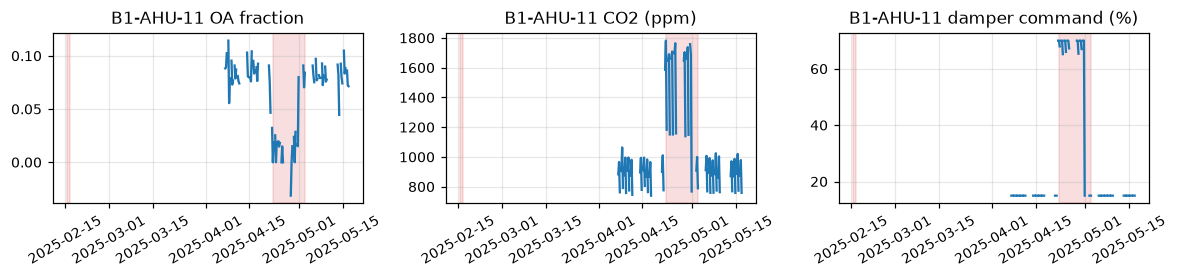

In [32]:
fa = al[~al.true_alarm]
print(fa)
x = w[(w.ahu_id == "B1-AHU-11") & w.timestamp.between("2025-04-07", "2025-05-19")]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.6), sharex=True)
for a, c, t in zip(ax, ["oaf", "co2_ppm", "oa_damper_cmd_pct"], ["OA fraction", "CO2 (ppm)", "damper command (%)"]):
    s = x.set_index("timestamp")[c].resample("6h").median(); a.plot(s); a.set_title(f"B1-AHU-11 {t}")
    for r in fa.itertuples(): a.axvspan(r.start, r.end, color="tab:red", alpha=0.15)
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout(); fig.savefig(FIG / "unlabelled_damper.png", dpi=170)

The charts show B1-AHU-11 from 22 April to 5 May. Outdoor-air fraction drops from 0.08 to 0.02, CO2 climbs by about 650 ppm, and
the controller opens the damper command from 15% to 70% with no effect. This looks like a stuck damper with
no work order, which would mean the labels are incomplete. Counting it as correct would leave one false alarm in 240 AHU-months
(B3-AHU-06 in February, about one day long). No technician has confirmed it, so the official count stays at 2 and this
is a lead for the client to check, not a result.

## 14. New AHU and fewer sensors

* **New AHU.** Hold out a quarter of the AHUs (stratified by building), fit the normal models and the
  classifier on the other units only, score the held-out ones, and repeat for all four quarters. This runs twice,
  (a) on day one with no history at all, and (b) after a 14-day listening period, where the normal models are
  refit with the new unit's first two healthy weeks (the classifier still never sees it, and the
  listening days are not scored).
* **Fewer sensors.** Re-run the out-of-fold evaluation with the CO2 residuals removed for every AHU
  (and the airflow indicator off). Airflow only enters through `flow_est`, which falls back to
  design airflow × fan speed, so CO2 is the sensor that matters.

In [33]:
exp = {"baseline": summary}
for name, drop in [("no CO2", ("co2",)), ("no CO2, no airflow", ("co2", "flow")), ("no mixed-air sensor", ("mat",))]:
    p, k = X.fewer_sensors(w, labels, drop)
    exp[name], _ = X.score(p, k, labels, AHU_MONTHS)
p, k = X.new_ahu(df, w, labels)
exp["new AHU, day one"], _ = X.score(p, k, labels, AHU_MONTHS)
p, k = X.new_ahu(df, w, labels, baseline_days=14)
exp["new AHU, after 14-day listening"], ev_new = X.score(p, k, labels, AHU_MONTHS * (1 - 14 / 181))
cmp = pd.DataFrame(exp).T[["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]]
cmp.astype(float).round(3)

,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month
baseline,27.0,22.0,9.333,2.0,0.008
no CO2,28.0,22.0,10.625,1.0,0.004
"no CO2, no airflow",27.0,21.0,11.167,3.0,0.012
no mixed-air sensor,27.0,20.0,12.333,8.0,0.033
"new AHU, day one",28.0,12.0,0.583,179.0,0.746
"new AHU, after 14-day listening",28.0,20.0,13.000,8.0,0.036


**Reading the table.** Losing CO2 costs almost nothing. With CO2 removed the model still finds all 28 events and types 22,
because the damper fault stays visible in the mixed-air temperature balance (outdoor-air fraction), and CO2 mainly makes it faster to confirm.
Removing CO2 leaves 28 found, 22 typed and 1 false alarm. Removing airflow as well gives 27 found, 21 typed and 3 false alarms (0.012 per AHU-month), so neither sensor is essential. The mixed-air temperature matters more. Without it the model still finds 27 and types 20, but false alarms rise from 2 to 8 (0.033 per AHU-month) and the median delay from 9.3 to 12.3 hours, because the outdoor-air fraction and the coil temperature drop both need it. A building with fewer sensors therefore gets the same model with those inputs missing (LightGBM handles NaN
natively), not a separate model, and a building without a mixed-air sensor keeps engineer review on damper alerts. These runs blank the classifier inputs only. The normal-behaviour models were still fitted with CO2 and the mixed-air temperature (the valve model uses it as an input), so each row is an upper bound on a building that never had the sensor.

A brand-new AHU is the real risk. On day one every fault is still found, but the normal models do not
know the unit's own operating point. The result is 179 false alarms (0.75 per AHU-month), roughly 90
times the in-sample rate on known units in this table (60 times the shipped 0.0125), and only 12 of 28 types are right. Two weeks of listening (data collected,
nothing sent to technicians) brings false alarms down to 8 (0.036 per AHU-month) and typing up to 20 of 28.
That is the onboarding rule used in Q3 and the recommendation in Q4. The 14 days are the first stretch of each unit with no work order nearby, chosen with the labels, which stands in for an engineer checking the unit is healthy. A real listening period can contain an unnoticed fault, so 8 is an optimistic figure.

In [34]:
json.dump({k: {m: float(v) for m, v in s.items()} for k, s in exp.items()},
          open(CODE_DIR / "outputs" / "experiments.json", "w"), indent=1)
ev_new.groupby("fault_type")[["detected", "type_ok"]].sum()

,detected,type_ok
fault_type,,
chw_valve_stuck,8,7
low_coil_capacity,7,3
oa_damper_stuck,7,7
sat_sensor_bias,6,3


For a new AHU after listening, stuck valves (7 of 8) and damper faults (7 of 7) are typed almost as well as on known units. The loss is in low coil capacity (3 of 7) and sensor bias (3 of 6), the two faults that are defined against the unit's own normal capacity, which two weeks of history only partly teaches. Technicians should treat those two types as "check the coil and the sensor" during a new unit's first months.

## 15. Final model and predictions

Normal models and classifier are refit on all of January to June and applied to July and August with the tuned
post-processing. `run()` repeats the steps above end to end.

In [35]:
sub, clf, _ = PL.run()
print(sub.fault_type.value_counts())
r = E.runs(sub, sub.fault_type)
r[(r.end - r.start) > pd.Timedelta("6h")]

fault_type
normal               682880
sat_sensor_bias       11302
oa_damper_stuck        7394
chw_valve_stuck        6584
low_coil_capacity      3834
Name: count, dtype: int64


,ahu_id,fault_type,start,end,rows
0,B1-AHU-01,chw_valve_stuck,2025-07-07 13:45:00,2025-07-15 11:00:00,2266
1,B1-AHU-03,low_coil_capacity,2025-07-09 08:55:00,2025-07-15 10:15:00,1741
2,B1-AHU-09,low_coil_capacity,2025-07-14 18:10:00,2025-07-21 16:15:00,1988
3,B1-AHU-12,low_coil_capacity,2025-07-22 10:15:00,2025-07-22 19:00:00,105
4,B1-AHU-12,sat_sensor_bias,2025-07-22 19:05:00,2025-08-08 10:05:00,4775
5,B1-AHU-16,chw_valve_stuck,2025-07-23 11:10:00,2025-07-29 08:55:00,1697
6,B2-AHU-07,oa_damper_stuck,2025-07-30 02:25:00,2025-08-05 21:05:00,1951
7,B2-AHU-12,oa_damper_stuck,2025-07-13 03:15:00,2025-07-25 04:30:00,3463
8,B3-AHU-01,oa_damper_stuck,2025-08-21 12:20:00,2025-08-28 10:05:00,1980
9,B3-AHU-03,sat_sensor_bias,2025-07-25 16:05:00,2025-07-29 11:20:00,1095


On July and August, 29,114 of 711,994 rows (4.1%) are flagged as a fault, close to the 5% fault share in the training months. The final model raises 11 sustained alarms (longer than 6 hours). The table shows 12 rows because the B1-AHU-12 alarm changes type once, spread over all four fault types and all three buildings, for example a stuck valve on B1-AHU-01 from 7 to 15 July and a damper fault on B2-AHU-12 from 13 to 25 July. The 105-row low-coil-capacity alarm on B1-AHU-12 on 22 July turns into sensor bias the same evening, and should be read as one event of sensor bias. I leave those 105 rows as the model labelled them in `predictions.csv`, because editing predictions by hand after looking at the test period would break the rule that the file is the model's own output. If the answer key calls this event sensor bias, those rows count as a wrong type. None of these alarms can be checked against labels, so 4.1% against 5% is a sanity check on volume, not evidence of accuracy.

In [36]:
import subprocess
r = subprocess.run([sys.executable, str(CODE_DIR / "starter" / "validate_submission.py"),
                      str(CODE_DIR.parent / "predictions.csv")], capture_output=True, text=True)
print(r.stdout, r.stderr[-2000:])
assert r.returncode == 0

OK: 711994 rows, format is valid
 


The starter validator accepts the file, which has 711,994 rows (one per AHU and 5-minute step in July and August) in the required format. This is the `predictions.csv` delivered with the report.

## 16. Looks like a fault, but no label (test period)

The final model is now fixed, so the July and August inputs can be opened for patterns for the first time. Until here
they were only checked for quality (sections 2 and 3). The next cell compares each unit's median fan speed, valve,
setpoint error and outdoor-air fraction in July and August with its own April to June level, and lists the eight units
that move most.

In [37]:
lead_cols = ["fan_speed_pct", "chw_valve_cmd_pct", "sat_err", "oaf"]
st = df[df.steady].assign(m=df.timestamp.dt.month)
base = st[st.m.isin([4, 5, 6])].groupby("ahu_id")[lead_cols].median()
chg = pd.concat({m: st[st.m == m].groupby("ahu_id")[lead_cols].median() - base for m in (7, 8)}, axis=1)
score = (chg / st.groupby("ahu_id")[lead_cols].std().pipe(lambda s: pd.concat({7: s, 8: s}, axis=1))).abs().max(axis=1)
top = score.sort_values(ascending=False).index[:8]
display(chg.round(2).loc[top])
vs_building = chg - chg.groupby(chg.index.str[:2]).transform("median")  # takes out what the whole building did that month
display(vs_building.round(2).loc[top])
long = E.runs(sub, sub.fault_type).assign(days=lambda d: ((d.end - d.start) / pd.Timedelta("1D")).round(1))
long[(long.days > 0.25) & long.ahu_id.isin(["B1-AHU-12", "B3-AHU-06", "B2-AHU-12", "B1-AHU-01"])]

7                                             8                               
          fan_speed_pct chw_valve_cmd_pct sat_err   oaf fan_speed_pct chw_valve_cmd_pct sat_err  oaf
ahu_id                                                                                              
B2-AHU-12          -0.9              -1.5     0.0 -0.04           1.6               1.3     0.0  0.0
B1-AHU-12          -6.6              -1.3     0.0  0.00          -2.3               0.6     0.0  0.0
B3-AHU-06          -6.3              -1.7     0.0  0.00          -6.3              -0.9     0.0  0.0
B1-AHU-16           3.6               2.3     0.1  0.00          -0.2              -0.1     0.0  0.0
B1-AHU-01          -4.0              -2.8    -0.1  0.01           2.5               2.2     0.0  0.0
B3-AHU-08          -2.2              -1.1     0.0  0.00           0.0               1.1     0.0 -0.0
B3-AHU-04          -0.2              -0.3     0.0 -0.00           2.3               1.9     0.0  0.0
B3-AHU-05           2.7               1.7     0.1  0.00           2.1               1.0     0.0  0.0

7                                             8                               
          fan_speed_pct chw_valve_cmd_pct sat_err   oaf fan_speed_pct chw_valve_cmd_pct sat_err  oaf
ahu_id                                                                                              
B2-AHU-12         -0.10              -0.8     0.0 -0.04          0.95              1.00     0.0 -0.0
B1-AHU-12         -5.60              -0.7     0.0  0.00         -2.95             -0.00     0.0  0.0
B3-AHU-06         -5.75              -1.3     0.0 -0.00         -6.60             -1.25     0.0  0.0
B1-AHU-16          4.60               2.9     0.1 -0.00         -0.85             -0.70     0.0  0.0
B1-AHU-01         -3.00              -2.2    -0.1  0.01          1.85              1.60     0.0  0.0
B3-AHU-08         -1.65              -0.7     0.0  0.00         -0.30              0.75     0.0 -0.0
B3-AHU-04          0.35               0.1     0.0 -0.00          2.00              1.55     0.0  0.0
B3-AHU-05          3.25               2.1     0.1  0.00          1.80              0.65     0.0  0.0

,ahu_id,fault_type,start,end,rows,days
0,B1-AHU-01,chw_valve_stuck,2025-07-07 13:45:00,2025-07-15 11:00:00,2266,7.9
3,B1-AHU-12,low_coil_capacity,2025-07-22 10:15:00,2025-07-22 19:00:00,105,0.4
4,B1-AHU-12,sat_sensor_bias,2025-07-22 19:05:00,2025-08-08 10:05:00,4775,16.6
7,B2-AHU-12,oa_damper_stuck,2025-07-13 03:15:00,2025-07-25 04:30:00,3463,12.1
11,B3-AHU-06,sat_sensor_bias,2025-07-24 15:35:00,2025-08-12 13:05:00,5432,18.9


Against April to June, three units stand out in the test period. B1-AHU-12 and B3-AHU-06 run their fans 6.6% and 6.3% slower in July with the valve roughly unchanged, and B2-AHU-12 takes in less outdoor air in July (OA fraction −0.04). In August B3-AHU-06 stays 6.3% slower while B1-AHU-12 comes back to −2.3%, and the second table gives the same picture (−5.6% and −5.75% in July). B3-AHU-06 is also one of the units the model confuses in section 13, so its July lead needs a site check before it counts. The longest test alarm, a stuck valve on B1-AHU-01 lasting 7.9 days (table above), shows no comparable seasonal shift and is the strongest lead for the client. None of these moves is large, but they persist for weeks, and the final model of section 15 raises sustained alarms on all three. They are worth a site check.

## 17. Behaviour tests

Good validation numbers do not prove that the model reacts to faults for the right reasons. The next cell edits 5,000
normal training rows in controlled ways. Directional tests push a fault signature into the inputs and expect the
probability of that fault to rise by more than 0.05. Invariance tests change something that should not matter (1% noise
on every reading, another building code) and expect a change below 0.02. The pass rules were fixed before the run.

In [38]:
def behaviour(X0):
    def p_of(X, classes):
        return PL.predict_proba(clf, X)[classes].sum(axis=1).mean()
    def edit(**set_to):
        X = X0.copy()
        for c, f in set_to.items():
            X[c] = f(X[c])
        return X
    add = lambda v: (lambda s: s + v)
    const = lambda v: (lambda s: s * 0 + v)
    fault = list(FAULTS)
    rng = np.random.default_rng(0)
    num = [c for c in cols if c not in ("building_code", "has_co2", "has_flow")]
    noisy = X0.copy(); noisy[num] = noisy[num] * (1 + rng.normal(0, 0.01, noisy[num].shape))
    cases = [
        ("SAT 3 °C above setpoint for 12 h", "P(any fault)", fault,
         edit(sat_err_med3h=add(3), sat_err_med12h=add(3), sat_off_3h=const(1), sat_off_12h=const(1)), "up"),
        ("valve 30 points above its normal model", "P(valve stuck or low coil)", ["chw_valve_stuck", "low_coil_capacity"],
         edit(r_valve_med3h=add(30), r_valve_med12h=add(30)), "up"),
        ("no outdoor air arrives and CO2 builds up", "P(damper stuck)", ["oa_damper_stuck"],
         edit(oaf_med3h=const(0), oaf_med12h=const(0), r_co2_med3h=add(300), r_co2_med12h=add(300)), "up"),
        ("SAT 3 °C high while the valve is fully open (full signature)", "P(any fault)", fault,
         edit(sat_err_med3h=add(3), sat_err_med12h=add(3), sat_off_3h=const(1), sat_off_12h=const(1),
              valve_hi_3h=const(1), valve_hi_12h=const(1), r_valve_med3h=add(30), r_valve_med12h=add(30)), "up"),
        ("no outdoor air, CO2 up, controller opens the damper (full signature)", "P(damper stuck)", ["oa_damper_stuck"],
         edit(oaf_med3h=const(0), oaf_med12h=const(0), r_co2_med3h=add(300), r_co2_med12h=add(300),
              r_damper_med3h=add(30), r_damper_med12h=add(30)), "up"),
        ("1% random noise on every reading", "P(any fault)", fault, noisy, "same"),
        ("same rows labelled as another building", "P(any fault)", fault,
         edit(building_code=lambda s: s % 3 + 1), "same"),
    ]
    rows = []
    for name, metric, cls, X, expect in cases:
        before, after = p_of(X0, cls), p_of(X, cls)
        ok = after > before + 0.05 if expect == "up" else abs(after - before) < 0.02
        rows.append(dict(test=name, metric=metric, before=before, after=after, expected=expect, passed=ok))
    flip = ((1 - PL.predict_proba(clf, noisy)["normal"] > 0.8) != (1 - PL.predict_proba(clf, X0)["normal"] > 0.8)).mean()
    return pd.DataFrame(rows), flip
probe = w[(w.split == "train") & (w.label == "normal") & ~w.near_event].sample(5000, random_state=0)
test_w = w[w.split == "test"]
held = test_w[(1 - PL.predict_proba(clf, test_w[cols])["normal"]).values < 0.05].sample(5000, random_state=0)  # never seen in training
t_train, alarm_flip = behaviour(probe[cols])
t_test, _ = behaviour(held[cols])
print(f"ahu_id or timestamp among the inputs: {bool({'ahu_id', 'timestamp'} & set(cols))}. "
      f"Rows crossing the 0.8 alarm threshold under 1% noise: {alarm_flip:.2%}")
t_train.assign(**{"after (test rows)": t_test.after, "passed (test rows)": t_test.passed}).round(3)

ahu_id or timestamp among the inputs: False. Rows crossing the 0.8 alarm threshold under 1% noise: 0.02%


,test,metric,before,after,expected,passed,after (test rows),passed (test rows)
0,SAT 3 °C above setpoint for 12 h,P(any fault),0.0,0.048,up,False,0.046,False
1,valve 30 points above its normal model,P(valve stuck or low coil),0.0,0.753,up,True,0.741,True
2,no outdoor air arrives and CO2 builds up,P(damper stuck),0.0,0.024,up,False,0.017,False
3,SAT 3 °C high while the valve is fully open (f...,P(any fault),0.0,0.981,up,True,0.980,True
4,"no outdoor air, CO2 up, controller opens the d...",P(damper stuck),0.0,0.205,up,True,0.171,True
5,1% random noise on every reading,P(any fault),0.0,0.001,same,True,0.000,True
6,same rows labelled as another building,P(any fault),0.0,0.000,same,True,0.000,True


Five of the seven tests pass and two fail, and the failures say something useful about the model. A single symptom on its own barely moves it. Pushing SAT 3 °C above setpoint for 12 hours raises P(any fault) from 0.000 to only 0.048, and removing outdoor air with CO2 rising raises P(damper stuck) to only 0.024, both below the 0.05 rule. When the same symptoms come with the rest of their physical signature, the model reacts strongly. SAT high with the valve fully open gives 0.981, and no outdoor air with CO2 up and the controller opening the damper gives 0.205. A raised valve residual alone gives 0.753 for a valve or coil fault. The invariance tests pass cleanly, since 1% noise moves P(any fault) by 0.001, a different building code moves it by less than 0.001, and only 0.02% of rows cross the 0.8 alarm threshold under noise. Neither `ahu_id` nor the timestamp is an input. The last two columns repeat every test on held-out July and August rows, and the numbers barely move (0.046, 0.741, 0.017, 0.980, 0.171, 0.000 and 0.000), with the same five passes and two failures, so the behaviour is not a quirk of the training rows.

The model therefore waits for a consistent signature rather than reacting to one reading, which is what keeps false alarms at 2 to 3 in 240 AHU-months. The cost is that a fault which shows only one symptom (for example a damper fault in a building without CO2, like the missed B3-AHU-05 event) is caught late or not at all. The pilot should keep the BMS supply-air alarm running alongside the model for exactly this case.

## 18. What it means for the maintenance team

The next cell turns the honest (nested) results into what each building's team would see, which is events found, right
types and wasted visits per year, and compares the wasted visits with today's alarm and the expert rules.

In [39]:
units = pd.Series({"B1": 16, "B2": 12, "B3": 12})
def per_building(ev_, al_):
    b_ev, b_fa = ev_.ahu_id.str[:2], al_[~al_.true_alarm].ahu_id.str[:2]
    t = pd.DataFrame({"AHUs": units, "events": ev_.groupby(b_ev).size(), "found": ev_.groupby(b_ev).detected.sum(),
                      "right type": ev_.groupby(b_ev).type_ok.sum(), "false alarms": b_fa.value_counts()}).fillna(0)
    t["false visits per year"] = t["false alarms"] * 2  # six scored months, so twice per year
    return t
_, _, al_rules = E.score_events(keys, E.alarms(methods["Expert rules"], keys, **PL.POST), labels, AHU_MONTHS)
_, _, al_bms = E.score_events(keys, E.alarms(methods["BMS SAT alarm (today)"], keys, **PL.POST), labels, AHU_MONTHS)
_, _, al_nested = E.score_events(keys, nested_pred, labels, AHU_MONTHS)
by_building = per_building(nested_ev, al_nested)
by_building.loc["fleet"] = by_building.sum()
visits = pd.DataFrame({name: [a[~a.true_alarm].shape[0] * 2] for name, a in
                       [("BMS SAT alarm", al_bms), ("Expert rules", al_rules), ("Model (nested)", al_nested)]},
                      index=["false visits per year, whole fleet"])
display(by_building.astype(int))
visits

,AHUs,events,found,right type,false alarms,false visits per year
B1,16,10,10,8,1,2
B2,12,6,6,6,0,0
B3,12,12,11,6,1,2
fleet,40,28,27,20,2,4


,BMS SAT alarm,Expert rules,Model (nested)
"false visits per year, whole fleet",16,18,4


Every building gets almost all of its faults found (10 of 10 in B1, 6 of 6 in B2, 11 of 12 in B3). Typing is
perfect in the hospital (6 of 6) and weakest in the mall (6 of 12), which has no CO2 sensor and holds two of the three
saturated units. Across the fleet the model would cause about 6 wasted visits a year, against 16 for the BMS alarm and 18
for the expert rules, while finding 27 faults instead of 14 or 19. Wasted visits are false alarms in six months times two,
which assumes that the second half of the year looks like the first and rests on only 3 false alarms. Right type as shipped is 75% (21 of 28) against the proposed target of 70%, with a 95% interval of 55% to 89%, so the target is met on the point estimate only.

**Decision.** The recommendation is a pilot, not a full rollout. On the honest estimate the model meets every
proposed target from section 0 (found 96% against 80%, right type 75% against 70%, median delay 10.0 hours against 24,
false alarms 0.0125 against 0.05 per AHU-month, all as shipped in section 12) and beats the BMS alarm event by event. The right-type margin is thin, with
a 95% interval of 55% to 89%, so the pilot starts in listening mode and sends tickets building by building (Q3 and Q4).
The saturated units B1-AHU-05, B3-AHU-02 and B3-AHU-09 get their alarms as "check the unit" without a fault type until a
separate saturated-unit mode is built.

**Fairness and personal data.** The data holds no personal data and the model makes no decision about people. It ranks
equipment for inspection. Fairness checks between groups of people and UU PDP therefore do not apply. The comparable check
is between buildings, and the table above shows that the mall is served worse on fault type, which is the segment to
watch in the pilot.

### Value in money, priced for an Indonesian building

The objective J weighs a false alarm as much as four missed fault types per AHU-month, a weight I chose myself. As a
check in money I use the figure of merit of Yuill and Braun (2017, International Journal of Refrigeration 74), worked out
in Yuill's thesis (Purdue 2014, chapter 7). It sums benefit minus service cost over every fault and every false alarm,
against a baseline without the tool. Two changes adapt it to this fleet. The baseline is what the labels record, so every
fault is repaired at its labelled end anyway and only the earlier repair and the wasted visits count. Benefit is energy
only, the extra electric kW of each fault times the tariff times the running hours between the first alarm plus the
response time and the labelled repair. A wrong type costs one wasted check of the predicted fault and a false alarm one
check at the mean service time. The BMS alarm names no fault, so it follows Yuill's no-diagnosis case (equation 7.21 of the thesis),
where the technician finds the fault half the time after half an hour and otherwise spends two more hours for nothing.

The data runs on UTC+8, which is WITA (Bali, Kalimantan Timur, Sulawesi), so every price is Indonesian and in rupiah.

| Input | Pessimistic | Central | Optimistic | Source |
|---|---|---|---|---|
| Extra kW per fault | measured | measured | measured | this data, `E.excess_kw` (next cell) |
| Chiller plant kW per ton of cooling | 0.56 | 0.62 | 1.61 | design, measured West Java mall, old air cooled plant ([Suamir et al., PNB](https://repository.pnb.ac.id/id/eprint/5907/1/Paper_28_PI_INSuamir_2019.pdf), [Thamrin Nine](https://www.johnsoncontrols.com/customer-stories/customer-success-stories/thamrin-nine)) |
| Tariff (Rp per kWh) | 1,114.74 | 1,114.74 | 1,444.70 | PLN B-3 above 200 kVA and B-2, unchanged Oct to Dec 2026 ([Kompas](https://money.kompas.com/read/2026/11/02/083952426/tarif-listrik-pln-november-2026-cek-daftar-lengkap-semua-golongan), [Disway](https://disway.id/read/977136/disway.id)) |
| Technician wage (Rp per month) | 9,000,000 | 5,000,000 | 3,499,878 | top of HVAC postings, typical building technician posting, UMK Denpasar 2026 ([Glints](https://glints.com/id/opportunities/jobs/teknisi-hvac/258988bd-3076-4ba4-ba7f-99cfa2799c47), [detik](https://www.detik.com/bali/bisnis/d-8271244/umk-denpasar-2026-naik-jadi-rp-3-499-juta)) |
| Loaded labour (Rp per hour) | 62,466 | 34,458 | 23,988 | wage over 173 hours, plus employer BPJS (JHT 3.7%, JP 2%, JKK 0.24 to 1.74%, JKM 0.3%, Kesehatan 4%) and THR of one month a year ([BPJS rates](https://employsome.com/?p=9909)) |
| Response time (hours) | 48 | 24 | 4 | "2x24 jam" repair promise of a manufacturer's service in Indonesia, routine and critical tiers of HVAC contracts ([GREE](https://www.qoo10.co.id/en/gadget/106532/gree-puts-round-the-clock-ac-support-and-48-hour-fixes-at-the-center-of-after-sales-care/), [OxMaint](https://oxmaint.com/article/hvac-maintenance-contract-sla-buyers-guide)) |

Two inputs are still estimates, and I say so. Service hours per fault (valve 2, damper 3, sensor 1.5, coil 4) follow
contractor guides that give 1 to 2 hours for an actuator swap and 2 to 4 hours for a motorised damper
([PickComfort](https://www.pickcomfort.com/air-conditioner-actuator-replacement-cost-typical-prices/)), because no
AHU labour standard was found for Indonesia and Yuill's own hours are for rooftop units. The chance that a technician
finds an undiagnosed fault stays at Yuill's structure with one half, since Yuill ties it to the capacity loss of refrigerant
faults, which has no equivalent here. Comfort, equipment life and faults that run for months unlabelled are not priced.

The next cell first measures the extra kW of each labelled fault against the same AHU's healthy rows in the 28 days around
it (same hour, weekday or weekend). Coil load is the sensible heat the brief gives, 1.207 times airflow in m3 per second
times the drop from mixed to supply air, turned into chiller kW with the kW per ton above, and fan power is added as
measured. A fault that cools less than normal saves chiller energy, so its kW is floored at zero. The tariff is flat with no time-of-day part, so the log's local clock (UTC+8, which is Central Indonesia time) does not change the price.

In [40]:
kw_ev = E.excess_kw(df[(df.split == "train") & df.steady], labels)
display(kw_ev.merge(labels[["ahu_id", "start", "fault_type"]]).groupby("fault_type")[["coil_kw", "fan_kw"]].agg(["mean", "min", "max"]).round(1))
preds = {"BMS SAT alarm (today)": E.alarms(methods["BMS SAT alarm (today)"], keys, **PL.POST),
         "Expert rules": E.alarms(methods["Expert rules"], keys, **PL.POST),
         "Logistic regression": E.alarms(oof_lr, keys, **LR_POST),
         "Model (in-sample)": pred_by[(0.8, 12, 144)], "Model (nested)": nested_pred}
money = {}
for name, p in preds.items():
    _, e, a = E.score_events(keys, p, labels, AHU_MONTHS)
    for scen, prices in E.SCENARIOS.items():
        money[(name, scen)] = E.value(e, a, AHU_MONTHS, kw=kw_ev, **prices, typed=not name.startswith("BMS"))
money = pd.DataFrame(money).T
display((money.xs("central", level=1)[["energy_rp", "visit_rp"]] / 1e3).round(0))
(money.rp_per_ahu_month.unstack()[list(E.SCENARIOS)] / 1e3).round(1)

coil_kw             fan_kw                
                     mean   min   max   mean  min        max
fault_type                                                  
chw_valve_stuck     -14.1 -48.3  13.1    4.7 -4.2  18.299999
low_coil_capacity    -4.4 -25.5   1.5    1.1 -0.0   4.900000
oa_damper_stuck      -1.5  -2.9  -0.3   -0.2 -2.0   0.200000
sat_sensor_bias       2.9 -28.9  26.3    1.4 -4.6   6.300000

,energy_rp,visit_rp
BMS SAT alarm (today),918.0,1413.0
Expert rules,570.0,1641.0
Logistic regression,2157.0,3080.0
Model (in-sample),4745.0,560.0
Model (nested),4746.0,749.0


,pessimistic,central,optimistic
BMS SAT alarm (today),-7.4,-2.1,-2.8
Expert rules,-10.4,-4.5,-2.9
Logistic regression,-16.2,-3.8,-1.8
Model (in-sample),12.2,17.4,38.5
Model (nested),10.8,16.7,37.9


The first table shows what the faults cost in this data. A stuck valve cuts coil cooling by 14.1 kW on average (the
zone runs warm) but adds 4.7 kW of fan power, because the fan speeds up to make up for it. A biased SAT sensor adds
2.9 kW of cooling and 1.4 kW of fan, since the unit overcools to reach a setpoint it misreads, and three of the five
B3 sensor faults add 19 to 26 kW each. Stuck dampers and low coil capacity change little, and their value is comfort and air
quality, which this sum does not price. The other two tables are in thousands of rupiah.

In the central scenario (PLN B-3 at Rp1,114.74 per kWh, Rp34,458 per labour hour, 24 hours to respond) the nested model
is worth Rp16,700 per AHU-month, about Rp8.0 million a year for the 40 AHUs. It earns Rp4.75 million of energy over the
six months and spends Rp749,000 on wasted checks. It is the only method above zero in every scenario, from Rp10,800 in
the pessimistic one to Rp37,900 in the optimistic one. The BMS alarm loses Rp2,100 to Rp7,400, the expert rules Rp2,900
to Rp10,400, and the logistic regression Rp1,800 to Rp16,200, because its 27 false alarms cost Rp3.08 million in visits.
The BMS alarm earns less in the optimistic scenario than in the central one because a less efficient chiller makes a
stuck valve save more cooling energy, so more of its events are floored at zero.

The amounts are small because the labelled faults were repaired within a median of about 6.5 days anyway, and Indonesian
electricity and labour are cheap next to the USD rates of Yuill's examples. The business case therefore rests on what
this sum leaves out, which is comfort, faults that today run for months without a work order (the unlabelled stuck damper
on B1-AHU-11 in Q1), and fewer wasted visits than the BMS alarm. In rupiah a false alarm (2.6 hours, Rp90,500) costs as
much as 0.42 right-typed faults earn (Rp4.75 million over 22 for the in-sample model). The J weight of four prices one at
0.47 of a right-typed fault, so the weight I chose sits close to what Indonesian prices imply.

The same value can also choose the alarm settings. The next cell scores all 16 settings of the tuning grid under each
scenario and compares the ranking with J.

In [41]:
grid_v = []
for g, p in pred_by.items():
    s, e, a = E.score_events(keys, p, labels, AHU_MONTHS)
    grid_v.append(dict(t_on=g[0], smooth=g[1], hold=g[2], J=E.objective(s), false_alarms=s["false_alarms"],
                       **{k: E.value(e, a, AHU_MONTHS, kw=kw_ev, **v)["rp_per_ahu_month"] for k, v in E.SCENARIOS.items()}))
grid_v = pd.DataFrame(grid_v)
print("Spearman correlation with J", grid_v[list(E.SCENARIOS)].corrwith(grid_v.J, method="spearman").round(2).to_dict())
print("best setting per scenario", {k: tuple(grid_v.loc[grid_v[k].idxmax(), ["t_on", "smooth", "hold"]]) for k in E.SCENARIOS})
grid_v.sort_values("central", ascending=False).head(6).round(3)

Spearman correlation with J {'pessimistic': 0.61, 'central': 0.22, 'optimistic': 0.03}
best setting per scenario {'pessimistic': (0.6, 36.0, 36.0), 'central': (0.7, 12.0, 36.0), 'optimistic': (0.7, 12.0, 36.0)}


,t_on,smooth,hold,J,false_alarms,pessimistic,central,optimistic
4,0.7,12,36,0.736,3,12295.942,17837.049,39850.128
5,0.7,12,144,0.736,3,12295.942,17837.049,39850.128
2,0.6,36,36,0.733,1,12312.073,17763.313,39616.971
3,0.6,36,144,0.733,1,12312.073,17763.313,39616.971
0,0.6,12,36,0.719,4,11538.739,17446.153,39650.607
1,0.6,12,144,0.719,4,11538.739,17446.153,39650.607


Every setting of the grid is worth between Rp16,900 and Rp17,800 per AHU-month in the central scenario, a spread of
about 5%. The best one (t_on 0.7, smoothing 12) earns Rp17,837 with 3 false alarms, while the setting J picks and the
bundle uses (t_on 0.8, smoothing 12, hold 144) earns Rp17,437 with 2, which is Rp400 less per AHU-month, about Rp190,000
a year for the fleet. The rank correlation with J is 0.61 in the pessimistic scenario, 0.22 in the central one and 0.03
in the optimistic one, low because the settings sit so close together in money that small differences in delay reorder
them. Money and J agree on the price of a false alarm (0.42 against 0.47 right-typed faults), and no setting is worth
switching for. The alarm settings therefore stay as they are, and the rupiah check is reported next to J. These rupiah figures are a lower bound on the value. They count energy and site visits only, take visit hours from a contractor guide rather than an Indonesian AHU standard, and assume a technician finds an unnamed fault half the time (Yuill and Braun's figure). Comfort, equipment life and faults left running for months are not priced, though they are a large part of why the client wants this.

## 19. Model bundle and experiment log

The next cell saves the final normal models, classifier, feature list and post-processing as one bundle, with a readable
`bundle.json` that records where the bundle came from (data hashes, code commit, library versions, seed and evaluation).

In [42]:
import hashlib, subprocess, joblib
from datetime import datetime, timezone
from ahu_fdd.config import DATA_DIR
BUNDLE = CODE_DIR / "outputs" / "model"; BUNDLE.mkdir(parents=True, exist_ok=True)
clean_normal = df.steady & (df.label == "normal") & ~df.near_event
normal_models = F.NormalModels(df.ahu_id.unique()).fit(df[clean_normal])  # same fit as inside run()
joblib.dump({"normal_models": normal_models, "classifier": clf, "features": cols, "post": PL.POST, "calibrator": calibrator}, BUNDLE / "bundle.joblib")
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()[:16]
data_files = ["ahu_train.parquet", "ahu_test.parquet", "fault_labels_train.csv", "ahu_metadata.csv"]
git = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=CODE_DIR, capture_output=True, text=True).stdout.strip()
dirty = subprocess.run(["git", "status", "--porcelain", "--", "src", "run.py", "requirements.txt"], cwd=CODE_DIR, capture_output=True, text=True).stdout.strip()
git = git + "+uncommitted" if git and dirty else git  # the stamp must point to the code that ran
meta_bundle = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "code_commit": git or "unknown",
    "data_sha256_16": {f: sha(DATA_DIR / f) for f in data_files},
    "libraries": {p: im.version(p) for p in ["pandas", "numpy", "pyarrow", "scikit-learn", "lightgbm", "scipy"]},
    "seed": SEED, "post_processing": PL.POST, "classifier_params": PL.CLF_PARAMS, "normal_model_params": F.LGB_PARAMS,
    "features": cols, "classes": CLASSES,
    "displayed_probability": "isotonic calibrator on out-of-fold P(fault), alarms use the raw score",
    "evaluation_oof_jan_jun": {"tuned_in_sample": {k: float(v) for k, v in summary.items()},
                               "nested": {k: float(v) for k, v in nested.items()}},
    "predictions_sha256_16": sha(CODE_DIR.parent / "predictions.csv"),
}
json.dump(meta_bundle, open(BUNDLE / "bundle.json", "w"), indent=1)
print(f"bundle.joblib {(BUNDLE / 'bundle.joblib').stat().st_size / 1e6:.1f} MB, bundle.json written")
pd.Series({k: v for k, v in meta_bundle.items() if isinstance(v, str)} | meta_bundle["data_sha256_16"])

bundle.joblib 5.3 MB, bundle.json written


created_utc                                       2026-11-10T22:02:55+00:00
code_commit                                             b62debb+uncommitted
displayed_probability     isotonic calibrator on out-of-fold P(fault), a...
predictions_sha256_16                                      f19ade444892bc66
ahu_train.parquet                                          58daad558b7b2ceb
ahu_test.parquet                                           ceb2d9c0080cd974
fault_labels_train.csv                                     09d0de7e1a6fcd5c
ahu_metadata.csv                                           8a86fceed3259a27
dtype: str

The bundle is 5.3 MB and its `bundle.json` records the code commit (printed above), the first 16 hex digits of the SHA-256 of each input file and of `predictions.csv` (f19ade444892bc66), and a note that the displayed probability passes through the isotonic calibrator while alarms use the raw score. Anyone holding the same four data files can check that the bundle was trained on them. The promotion rule in Q3 (labelled replay with McNemar's test, then a shadow run) is a design. It has not been run against a second bundle, because only one exists.

The next cell writes every run made in this notebook into one experiment log, stamped with the data hash and
the code commit, and summarises it by kind.

In [43]:
METRICS = ["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]
log_rows = [dict(experiment=f"tuning t_on={r.t_on} smooth={r.smooth} hold={r.hold}", kind="post-processing grid",
                 **r[METRICS].to_dict()) for _, r in grid.iterrows()]
for name, (s, _) in scored.items():
    log_rows.append(dict(experiment=name, kind="baseline vs model", **{k: s[k] for k in METRICS}))
for seed, r in seeds.iterrows():
    log_rows.append(dict(experiment=f"classifier seed {seed}", kind="seed spread", **r.to_dict()))
for name, s in exp.items():
    log_rows.append(dict(experiment=name, kind="new AHU and sensors", **{k: s[k] for k in METRICS}))
log_rows.append(dict(experiment="nested post-processing tuning", kind="honest estimate", **{k: nested[k] for k in METRICS}))
experiment_log = pd.DataFrame(log_rows).assign(data=meta_bundle["data_sha256_16"]["ahu_train.parquet"], commit=meta_bundle["code_commit"])
experiment_log.to_csv(CODE_DIR / "outputs" / "experiment_log.csv", index=False)
print(len(experiment_log), "experiments logged")
experiment_log.groupby("kind").agg(runs=("experiment", "size"), best_type_ok=("type_ok", "max"), fewest_false_alarms=("false_alarms", "min"))

32 experiments logged


,runs,best_type_ok,fewest_false_alarms
kind,,,
baseline vs model,4,22.0,2.0
honest estimate,1,20.0,2.0
new AHU and sensors,6,22.0,1.0
post-processing grid,16,22.0,1.0
seed spread,5,22.0,2.0


The experiment log holds 32 runs. The four method comparisons (BMS alarm, expert rules, logistic regression and model) top out at 22 named events and 2 false alarms, the 16 post-processing settings at 22 named and 1 false alarm, and the five seeds at 22 named and 2 false alarms. The honest nested estimate is the single run with 20 named, and the five new-AHU and missing-sensor runs reach 1 false alarm at best. Every number in this notebook can be traced to one of these rows.

**Promotion of a new version.** A challenger replaces the champion only after two gates. The first is a replay
on the labelled months, compared event by event with the McNemar test as in section 11. The second is a shadow run on the
fleet. A one-week shadow on 40 AHUs covers about 9 AHU-months, where fewer than one false alarm is expected, so it cannot
tell two versions apart. With no unconfirmed alarm in 30 AHU-months, the 95% upper bound on the false-alarm rate is 3/30,
or 0.1 per AHU-month, which takes a little over three weeks on 40 AHUs. Rollback means loading the previous bundle.

## 20. Monitoring plan

The next cell measures input drift with the population stability index (PSI) for the ten most important features plus
outdoor and chilled-water temperature, comparing January to June with July and August. Each value is read against the
largest PSI seen between two training months, because some features swing a lot even without a fault. It also compares
the share of rows in alarm.

In [44]:
def psi(a, b, bins=10):
    a, b = a.dropna(), b.dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    pa = np.clip(np.histogram(a, edges)[0] / len(a), 1e-4, None)
    pb = np.clip(np.histogram(b, edges)[0] / len(b), 1e-4, None)
    return float(((pb - pa) * np.log(pb / pa)).sum())
imp = pd.Series(clf.booster_.feature_importance("gain"), index=cols).sort_values(ascending=False)
watch = list(imp.index[:10]) + ["oat_c", "chwst_c"]
train_w, test_w = w[w.split == "train"], w[w.split == "test"]
mon = pd.DataFrame({
    "PSI Jan-Jun vs Jul-Aug": {c: psi(train_w[c], test_w[c]) for c in watch},
    "largest PSI between training months": {c: max(psi(train_w.loc[train_w.month != k, c], train_w.loc[train_w.month == k, c]) for k in range(1, 7)) for c in watch},
})
now, past = mon["PSI Jan-Jun vs Jul-Aug"], mon["largest PSI between training months"]
mon["status"] = np.where(now > 0.3, "act", np.where((now > 0.2) & (now > past), "watch", "ok"))  # the rule in the table below
nz = lambda d: (d.r_damper_med12h.abs() > 1).mean()  # damper more than 1 point away from its normal model
print("damper residual non-zero share, Jan-Jun", round(nz(train_w), 4), "| Jul-Aug", round(nz(test_w), 4),
      "| training months", {k: round(nz(train_w[train_w.month == k]), 4) for k in range(1, 7)})
live = test_w[["ahu_id", "timestamp"]].merge(sub, on=["ahu_id", "timestamp"], how="left")
alarm_share = pd.Series({"Jan-Jun out of fold": (pred != "normal").mean(), "Jul-Aug live": (live.fault_type != "normal").mean()})
print("share of rows in alarm:", alarm_share.round(4).to_dict())
mon.round(3)

damper residual non-zero share, Jan-Jun 0.0767 | Jul-Aug 0.0885 | training months {1: np.float64(0.0849), 2: np.float64(0.0848), 3: np.float64(0.0672), 4: np.float64(0.0709), 5: np.float64(0.0764), 6: np.float64(0.0756)}
share of rows in alarm: {'Jan-Jun out of fold': 0.0253, 'Jul-Aug live': 0.0378}


,PSI Jan-Jun vs Jul-Aug,largest PSI between training months,status
r_valve_med12h,0.022,0.087,ok
valve_coil_corr_12h,0.001,0.010,ok
r_valve_med3h,0.008,0.027,ok
oaf_med3h,0.001,0.003,ok
r_fan_med12h,0.055,0.007,ok
oaf_med12h,0.001,0.007,ok
r_co2_med12h,0.223,0.255,ok
building_code,0.000,0.005,ok
r_fan_med3h,0.034,0.005,ok
r_damper_med12h,0.074,0.773,ok


All twelve watched inputs are rated ok, and eleven have PSI at most 0.074. The 12-hour CO2 residual moves most, at 0.223, which the rule clears because training months already differ from each other by up to 0.255 on the same feature, so this is the normal swing of occupancy rather than new drift. The fan-power residuals are small (0.055 and 0.034) but larger than anything seen between training months (0.007 and 0.005), which fits filters loading up through the year and is the first input to watch in the pilot. Outdoor temperature (0.013) and chilled-water temperature (0.002) barely move. The damper residual has a large PSI between training months (0.773) because it sits at exactly zero most of the time and its bins are unstable, so its monitor should track the share of non-zero rows instead. That share is 7.67% in January to June and 8.85% in July and August, a little above the 6.7% to 8.5% range of single training months, which fits the extra damper alarms in the test period. The share of rows in alarm rises from 2.5% out of fold to 3.8% in July and August, in line with the 11 sustained alarms in section 15.

The alarms that keep the model honest after go-live are listed below. Retraining is triggered by these events,
not only by the calendar, and every retrained version still passes both promotion gates in section 19.

| Signal | Watch | Act | Response |
|---|---|---|---|
| Input drift (PSI on the 12 watched inputs) | above 0.2 and above the largest PSI between training months | above 0.3 in more than one building | check sensors and schedules, retrain if the change is real |
| Precision on confirmed tickets | more than 5 points below the previous quarter | 4 weeks in a row | review the false alarms, retrain with the new labels |
| Share of rows in alarm | above 6% | above 8% for a week | look for a plant-wide change before blaming the model |
| New confirmed faults | 10 since the last fit | | scheduled retrain |
| Scoring job | batch more than 15 minutes late or failing | twice in one day | page the engineer on call, alarms keep their last state |
| Setpoint or schedule change on an AHU | any change | | 14-day listening refit of the normal models for that AHU |

The alarm-share levels sit at about 1.6 and 2 times the 3.8% seen in July and August, so the live volume measured above does not trip them, while a building where every unit starts alarming does.

## 21. Conclusions, decision and limitations

**Findings.** On January to June, scored out of fold with the alarm thresholds tuned inside the folds, the model finds 27 of 28 labelled faults (95% interval 82% to 100%), names 21 correctly (55% to 89%) and raises 3 false alarms in 240 AHU-months (0.0125 per AHU-month) with the shipped 12-hour hold. Letting the folds pick the hold as well gives 20 and 2, with thresholds tuned on the scored months it names 22 (59% to 92%), and across five seeds 21 or 22. Median delay is 10.0 hours as shipped, with stuck valves and damper faults caught in about 2 hours and slow coil and sensor faults in about a day. It beats today's BMS alarm (14 found, 8 false alarms), the expert rules (19 found, 10 named, 9 false alarms) and a logistic regression on the same features (25 found, 17 named, 27 false alarms). The three gaps against the BMS alarm and the rules survive the Holm correction. Against the logistic regression the false-alarm gap is large (2 against 27 in sample), while the typing gap (6 to 1) is not proven on 28 events. For the maintenance team this means about 6 wasted visits a year across the fleet instead of 16 today.

**Decision.** Go to a pilot in listening mode, then send tickets building by building as described in Q3 and Q4. Send alarms on the three saturated units without a fault type until a separate mode exists, and keep the BMS supply-air alarm running alongside the model.

**Limitations.**

* Only 28 labelled events exist, so one more or one fewer right type moves the share by 4 points.
* Labels are incomplete. One false alarm looks like an unlabelled stuck damper (not confirmed by a technician), so the real false-alarm rate may be lower and the real miss rate is unknown.
* The headline is a known-unit number. Leakage across units is tested only in section 14, and its 14-day listening window is the first stretch with no work order, which uses the labels, so the 8 false alarms after listening are optimistic.
* The fewer-sensor runs blank the classifier inputs only. The normal-behaviour models were still fitted with CO2 and the mixed-air temperature, so those two rows are upper bounds on a building that never had the sensor.
* The expert-rule thresholds were tuned on the months they are scored on, which favours the rules rather than the model.
* The three chronically saturated units hold half of the six errors in the in-sample run (section 13).
* There are no zone temperatures and airflow is measured only in B2, so low coil capacity and sensor bias stay hard to tell apart.
* The model needs a consistent signature (section 17), so a fault with only one visible symptom is caught late.
* A new AHU needs 14 days of listening (179 false alarms on day one, 8 after listening).
* Displayed probabilities are recalibrated (Brier 0.0048 to 0.0040), but the middle range rests on few rows and should be rechecked once pilot labels arrive.
* July and August carry no labels, so the test-period numbers are alarm counts, not accuracy.